[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamezquita/PROYECTO-DEEP-LEARNING-NOTICIAS/blob/main/comparacion_regimenes_transferencia.ipynb)

# ¿Qué régimen de transferencia conviene? Cuerpo congelado, descongelamiento parcial y ajuste fino completo de RoBERTa-BNE

**Proyecto Integrador · Deep Learning · Fase 3**
Miguel Ángel Amézquita Briceño · Lis Alejandra Sánchez Moreno

## Por qué existe este cuaderno

En la Fase 1 el profesor pidió una comparación concreta: *"en la Fase 2 corran las dos configuraciones
—cuerpo congelado y ajuste fino completo— sobre la misma partición y reporten ambas"*. En la Fase 2 no
la hicimos: hicimos una búsqueda bayesiana de hiperparámetros, que explicó por qué RoBERTa-BNE colapsaba
con la configuración del artículo, pero que responde otra pregunta. La retroalimentación de la Fase 2 lo
dejó como **deuda de dos fases** y lo ligó al criterio C3 de la rúbrica: *"modelo preentrenado y alcance
del descongelamiento justificados con evidencia; al menos una configuración alternativa contrastada"*.

Este cuaderno salda esa deuda y nada más. Responde una sola pregunta:

> **Con la misma partición, el mismo protocolo de entrenamiento y la misma regla de selección,
> ¿cuánto del modelo hay que descongelar para clasificar noticias políticas colombianas, y vale lo que cuesta?**

## Qué se compara

| Régimen | Qué se entrena | Parámetros entrenables (aprox.) | Pregunta que responde |
|---|---|---|---|
| **Congelado** | Solo la cabeza de clasificación; el cuerpo de RoBERTa-BNE queda fijo como extractor de características | ~0,6 M de ~125 M (0,5 %) | ¿Basta con la representación preentrenada tal como viene? |
| **Parcial** | Las 2 últimas capas del codificador + la cabeza | ~14,8 M (12 %) | ¿Alcanza con adaptar las capas más cercanas a la tarea? |
| **Completo** | Todo el modelo (lo que hacen el artículo y nuestra Fase 2) | ~125 M (100 %) | ¿Hace falta mover todo el modelo? |

El régimen parcial no lo pidió el profesor. Lo agregamos porque con solo dos puntos (0 % y 100 %) no se
puede ver si la relación entre lo que se descongela y lo que se gana es gradual o de todo o nada.

## Cómo se garantiza que la comparación es justa

1. **Misma partición que la Fase 2**, verificada fila por fila (§7). Ver la advertencia de esa sección:
   recalcularla con otra versión de scikit-learn da una partición distinta.
2. **Mismo protocolo para los tres regímenes**: el ganador de la búsqueda bayesiana de la Fase 2
   (lote 8, *dropout* 0,0726, *weight decay* 0,00855, reducción de tasa sobre meseta y parada temprana
   sobre F1-macro de validación). Lo único que cambia es qué se descongela y la tasa de aprendizaje.
3. **La tasa de aprendizaje de cada régimen se elige en validación**, con una rejilla pequeña declarada
   antes de correr (§2). Una cabeza sola necesita una tasa mucho mayor que el modelo completo; usar la
   misma para todos sería comparar un régimen bien ajustado contra uno mal ajustado.
4. **Varias semillas**: la tasa se elige con la semilla 16 y luego cada régimen se corre con **tres
   semillas distintas** (42, 2026 y 7) que no participaron en la elección. Se reporta media ± desviación.
5. **El conjunto de prueba no decide nada.** La regla para elegir el régimen se fija en §2, la elección se
   hace solo con validación y se guarda con fecha (§16) **antes** de mostrar una sola cifra de prueba (§17).
6. **Se reportan todas las corridas**, incluidas las que salgan mal, con su curva por época.

## Qué NO hace este cuaderno

- No repite la búsqueda bayesiana ni la auditoría de interpretabilidad (están en
  `finetuning_bayesiano_colombia.ipynb` y `auditoria_interpretabilidad_modelo.ipynb`).
- No cambia la partición a temporal. Esa es la siguiente pregunta de la Fase 3 y necesita su propio cuaderno.
- No resuelve el atajo de fuente: con la partición actual, cualquier régimen puede aprovecharlo (ver §20).

## Requisitos

- Colab con **GPU** (Entorno de ejecución → Cambiar tipo de entorno → T4). Sin GPU no termina.
- Tiempo estimado en una T4: **entre 60 y 90 minutos**. La §13 lo mide en tu máquina antes de empezar.
- Opcional pero recomendado: **montar Google Drive** (§3). Cada corrida se guarda al terminar y, si Colab
  se desconecta, al volver a ejecutar se retoma donde quedó sin repetir nada.

## §1 · Instalación e importaciones

Todo el cuaderno usa PyTorch, igual que los cuadernos de línea base de la Fase 2. No usamos TensorFlow:
`transformers` 5.0 eliminó las clases `TF*` y la búsqueda bayesiana necesitó varios parches para correr
(ver README). El protocolo de la búsqueda se traduce a PyTorch en §12, línea por línea.

In [ ]:
import importlib.util, subprocess, sys
faltan = [p for p in ["transformers", "huggingface_hub", "openpyxl"] if importlib.util.find_spec(p) is None]
if faltan:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltan], check=True)

In [ ]:
import os, sys, json, time, math, random, hashlib, platform, re, unicodedata, zlib, base64, shutil, glob
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import TensorDataset, DataLoader

import sklearn
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, confusion_matrix)
from scipy.stats import binomtest

import transformers
from transformers import AutoTokenizer, AutoConfig, AutoModelForSequenceClassification

transformers.logging.set_verbosity_error()   # oculta el aviso de "cabeza nueva" en cada carga
transformers.logging.disable_progress_bar()
EN_COLAB = "google.colab" in sys.modules
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Python       :", platform.python_version())
print("torch        :", torch.__version__)
print("transformers :", transformers.__version__)
print("scikit-learn :", sklearn.__version__)
print("Dispositivo  :", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")
if DEVICE.type != "cuda":
    print("\n⚠️  No hay GPU. El régimen congelado corre en CPU en minutos, pero el parcial y el completo "
          "tardarían horas.\n    Cambia el tipo de entorno a T4 antes de seguir.")

Python       : 3.13.16
torch        : 2.14.1+cu130
transformers : 5.22.1
scikit-learn : 1.6.1
Dispositivo  : Tesla T4


## §2 · Configuración (todo lo que se decide antes de ver resultados)

Esta celda es el **preregistro** del experimento: las rejillas de tasas de aprendizaje, las semillas y la
regla para elegir el régimen quedan escritas aquí antes de entrenar. Si después se cambian, el informe
tiene que decirlo.

**Por qué estas rejillas de tasa de aprendizaje.**

- *Congelado*: solo se entrena la cabeza (dos capas densas sobre el vector `[CLS]`). Las tasas típicas para
  una cabeza lineal están entre 1e-4 y 3e-3; probamos cuatro porque cada corrida tarda segundos.
- *Parcial*: probamos la tasa ganadora del ajuste completo (4,1e-5) y una mayor (1,5e-4), porque con menos
  parámetros libres suele hacer falta una tasa más alta.
- *Completo*: la ganadora de la búsqueda bayesiana (4,1e-5) y la mitad (2e-5), entre la del artículo
  (1e-5, que colapsó en la Fase 2) y la ganadora.

**Regla de selección del régimen** (se aplica en §16, solo con validación): gana el régimen con mayor
F1-macro medio en validación sobre las tres semillas de evaluación. Si la diferencia con el siguiente es
menor que la mayor de sus dos desviaciones estándar, se considera empate y gana el que entrena menos
parámetros, porque es más barato y no hay evidencia de que el otro sea mejor.

In [ ]:
CONFIG = {
    # ---------- DATOS (el mismo corpus de 3.259 noticias de la Fase 2) ----------
    "url_corpus": ("https://raw.githubusercontent.com/mamezquita/PROYECTO-DEEP-LEARNING-NOTICIAS/"
                   "main/Segunda%20entrega/Dataset_politica_colombiana.xlsx"),
    "ruta_corpus": "dataset_politica_colombiana_3259.xlsx",
    "md5_corpus": "c432dac79cb39f80e503481411bd35db",   # el mismo MD5 que reporta la Fase 2
    "col_id": "id", "col_label": "label", "col_titulo": "title",
    "col_descripcion": "description", "col_fecha": "date",
    "campos_texto": ["title", "description"],
    "etiquetas": {"0": "falsa", "1": "real"},

    # ---------- PARTICIÓN (idéntica a la Fase 2; ver §7) ----------
    "seed_particion": 16,
    "proporciones": [0.70, 0.15, 0.15],
    "conteos_fase2": {"train": {0: 1187, 1: 1171}, "val": {0: 221, 1: 231}, "test": {0: 218, 1: 231}},

    # ---------- MODELO ----------
    "modelo_candidatos": [
        "PlanTL-GOB-ES/roberta-base-bne",   # el del artículo (hoy vaciado)
        "BSC-LT/roberta-base-bne",          # exige token de Hugging Face
        "BSC-TeMU/roberta-base-bne",        # exige token de Hugging Face
        "IsGarrido/roberta-base-bne",       # espejo público que usamos en la Fase 2
    ],
    "modelo_respaldo": "bertin-project/bertin-roberta-base-spanish",
    # Revisión fijada: el mismo commit del espejo que usaron todos los cuadernos de la Fase 2.
    "revisiones": {"IsGarrido/roberta-base-bne": "3d54a71ddc029cc1f8dd604e3b7bc0da0e2f7cd9"},
    "max_seq_length": 128,

    # ---------- PROTOCOLO COMÚN: ganador de la búsqueda bayesiana (Fase 2) ----------
    "batch_size": 8,
    "dropout": 0.07258496356733739,
    "weight_decay": 0.008547485565344062,
    "lr_reduce_factor": 0.3323028659735827,
    "lr_reduce_patience": 1,
    "min_lr": 1e-7,
    "early_stopping_patience": 3,
    "metrica_seleccion": "f1_macro",
    "usar_amp": True,          # precisión mixta en GPU (la búsqueda en Keras usó float32; ver §12)

    # ---------- REGÍMENES (preregistrados) ----------
    "regimenes": {
        "congelado": {"capas_abiertas": 0,  "lrs": [1e-4, 3e-4, 1e-3, 3e-3], "epocas_techo": 40},
        "parcial":   {"capas_abiertas": 2,  "lrs": [4.0983871094082436e-05, 1.5e-4], "epocas_techo": 15},
        "completo":  {"capas_abiertas": 12, "lrs": [2e-5, 4.0983871094082436e-05], "epocas_techo": 15},
    },
    "seed_seleccion": 16,              # elige la tasa de cada régimen
    "seeds_evaluacion": [42, 2026, 7], # no participan en la elección de la tasa

    # ---------- LÍNEA BASE CLÁSICA (la ganadora de la Fase 2, sin volver a buscar) ----------
    "tfidf": {"ngram_range": (1, 2), "min_df": 2, "C": 1.0, "max_features": 300_000, "sublinear_tf": True},
    "tfidf_f1_fase2": 0.9354,

    # ---------- SALIDA ----------
    "usar_drive": True,
    "dir_drive": "/content/drive/MyDrive/DL_fase3_regimenes",
    "dir_local": "resultados_regimenes",
    "guardar_pesos_seleccionado": True,   # ~500 MB en Drive para el régimen elegido

    # ---------- PRUEBA DE CABLEADO ----------
    # True: submuestra pequeña y 2 épocas, solo para comprobar que todo corre. Sus resultados NO sirven
    # para el informe y se guardan en una carpeta aparte.
    "modo_prueba": False,
}

print(json.dumps({k: v for k, v in CONFIG.items() if k != "conteos_fase2"}, indent=2,
                 ensure_ascii=False, default=str))

{
  "url_corpus": "https://raw.githubusercontent.com/mamezquita/PROYECTO-DEEP-LEARNING-NOTICIAS/main/Segunda%20entrega/Dataset_politica_colombiana.xlsx",
  "ruta_corpus": "dataset_politica_colombiana_3259.xlsx",
  "md5_corpus": "c432dac79cb39f80e503481411bd35db",
  "col_id": "id",
  "col_label": "label",
  "col_titulo": "title",
  "col_descripcion": "description",
  "col_fecha": "date",
  "campos_texto": [
    "title",
    "description"
  ],
  "etiquetas": {
    "0": "falsa",
    "1": "real"
  },
  "seed_particion": 16,
  "proporciones": [
    0.7,
    0.15,
    0.15
  ],
  "modelo_candidatos": [
    "PlanTL-GOB-ES/roberta-base-bne",
    "BSC-LT/roberta-base-bne",
    "BSC-TeMU/roberta-base-bne",
    "IsGarrido/roberta-base-bne"
  ],
  "modelo_respaldo": "bertin-project/bertin-roberta-base-spanish",
  "revisiones": {
    "IsGarrido/roberta-base-bne": "3d54a71ddc029cc1f8dd604e3b7bc0da0e2f7cd9"
  },
  "max_seq_length": 128,
  "batch_size": 8,
  "dropout": 0.07258496356733739,
  "weight_d

## §3 · Carpeta de resultados y reanudación

Cada corrida (régimen × tasa × semilla) escribe su carpeta en `runs/` apenas termina: historial por época,
métricas, predicciones de validación y de prueba. Si una carpeta ya existe, la corrida se salta. Así, si
Colab se desconecta a mitad de camino, basta con volver a ejecutar todo: lo terminado no se repite.

In [ ]:
DIR_BASE = CONFIG["dir_local"]
if CONFIG["usar_drive"] and EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DIR_BASE = CONFIG["dir_drive"]
if CONFIG["modo_prueba"]:
    DIR_BASE = DIR_BASE.rstrip("/") + "_PRUEBA"

DIR_RUNS = os.path.join(DIR_BASE, "runs")
os.makedirs(DIR_RUNS, exist_ok=True)
hechas = sorted(os.listdir(DIR_RUNS))
print(f"Resultados en: {DIR_BASE}")
print(f"Corridas ya terminadas: {len(hechas)}")
if CONFIG["modo_prueba"]:
    print("\n⚠️  MODO PRUEBA activo: resultados solo para verificar el cableado, no para el informe.")

Mounted at /content/drive
Resultados en: /content/drive/MyDrive/DL_fase3_regimenes
Corridas ya terminadas: 0


## §4 · Reproducibilidad

Mismas semillas en `random`, NumPy y PyTorch, y cuDNN en modo determinista. Aun así, en GPU dos corridas
con la misma semilla pueden diferir en los últimos decimales (sumas en paralelo en distinto orden). Por eso
la variabilidad se mide con varias semillas en vez de suponer que una sola corrida es "el" resultado: es
exactamente lo que nos pasó en la Fase 2, donde los mismos hiperparámetros dieron 0,951, 0,964 y 0,969.

In [ ]:
def fijar_semillas(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

fijar_semillas(CONFIG["seed_particion"])
print("Semillas fijadas.")

Semillas fijadas.


## §5 · Corpus: descarga, huella y limpieza

Se descarga el mismo archivo de la Fase 2 desde el repositorio y se comprueba su MD5. La limpieza es la
misma función de `Ejecucion_final_colombia_baseline_roberta_bne3259.ipynb`, copiada sin cambios para que
el texto que ve el modelo sea idéntico (incluida la expresión regular mal escapada que el README documenta:
se conserva a propósito, porque corregirla cambiaría el texto de entrada respecto a la Fase 2).

In [ ]:
def md5_archivo(ruta):
    h = hashlib.md5()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()


if not os.path.exists(CONFIG["ruta_corpus"]):
    try:
        import urllib.request
        urllib.request.urlretrieve(CONFIG["url_corpus"], CONFIG["ruta_corpus"])
        print("Corpus descargado del repositorio.")
    except Exception as e:
        print(f"No se pudo descargar ({type(e).__name__}).")
        if EN_COLAB:
            from google.colab import files
            print("Sube Dataset_politica_colombiana.xlsx (carpeta 'Segunda entrega' del repo):")
            subido = files.upload()
            os.rename(next(iter(subido)), CONFIG["ruta_corpus"])
        else:
            raise

md5 = md5_archivo(CONFIG["ruta_corpus"])
print(f"MD5: {md5}")
assert md5 == CONFIG["md5_corpus"], ("El archivo no es el corpus de la Fase 2. "
                                     "Revisa que sea el de 'Segunda entrega/'.")
print("✓ Es el mismo archivo que usó la Fase 2.")

Corpus descargado del repositorio.
MD5: c432dac79cb39f80e503481411bd35db
✓ Es el mismo archivo que usó la Fase 2.


In [ ]:
def cargar_y_limpiar(ruta, cfg):
    col_l, col_t, col_d, col_f = cfg["col_label"], cfg["col_titulo"], cfg["col_descripcion"], cfg["col_fecha"]
    df = pd.read_excel(ruta)
    print(f"Filas leídas: {len(df):,}")
    df = df.copy()
    for c in [col_t, col_d]:
        df[c] = df[c].fillna("").astype(str).str.strip()
    partes = [df[c] for c in cfg["campos_texto"] if c in df.columns]
    df["texto"] = partes[0]
    for p in partes[1:]:
        df["texto"] = (df["texto"] + ". " + p).str.replace(r"\\.\\s*\\.", ".", regex=True)
    df["texto"] = df["texto"].str.strip()
    n0 = len(df)
    df = df[df["texto"].str.len() > 0]
    df[col_l] = pd.to_numeric(df[col_l], errors="coerce")
    df = df[df[col_l].isin([0, 1])]
    df[col_l] = df[col_l].astype(int)
    print(f"Descartadas por texto vacío o etiqueta inválida: {n0 - len(df):,}")
    n1 = len(df)
    df = df.drop_duplicates(subset=[col_t, col_d, col_l])
    print(f"Duplicados exactos eliminados: {n1 - len(df):,}")
    df = df.reset_index(drop=True)
    df.insert(0, "row_id", np.arange(len(df)))
    return df


df = cargar_y_limpiar(CONFIG["ruta_corpus"], CONFIG)
COL_LABEL = CONFIG["col_label"]
print(f"\nCorpus: {len(df):,} noticias · {df[COL_LABEL].value_counts().sort_index().to_dict()} (0 = falsa, 1 = real)")

Filas leídas: 3,259
Descartadas por texto vacío o etiqueta inválida: 0
Duplicados exactos eliminados: 0

Corpus: 3,259 noticias · {0: 1626, 1: 1633} (0 = falsa, 1 = real)


## §6 · Agrupamiento anti-fuga

Igual que en la Fase 2: unión-búsqueda sobre título y descripción normalizados, para que dos variantes de
la misma noticia nunca queden una en entrenamiento y otra en prueba. Se copia sin cambios.

In [ ]:
def normalizar_texto(s: str) -> str:
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()
    s = re.sub(r"[^a-z0-9 ]", " ", s)
    return re.sub(r"\s+", " ", s).strip()


def asignar_grupos(df, cfg):
    parent = {}

    def find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[ra] = rb

    tits = df[cfg["col_titulo"]].map(normalizar_texto).values
    descs = df[cfg["col_descripcion"]].map(normalizar_texto).values
    for i in range(len(df)):
        if tits[i]:
            union(("row", i), ("tit", tits[i]))
        if descs[i]:
            union(("row", i), ("des", descs[i]))
    raices = [find(("row", i)) for i in range(len(df))]
    codigo = {r: k for k, r in enumerate(dict.fromkeys(raices))}
    return np.array([codigo[r] for r in raices])


df["grupo"] = asignar_grupos(df, CONFIG)
print(f"Grupos: {df['grupo'].nunique():,} (la Fase 2 reporta 3.238)")

Grupos: 3,238 (la Fase 2 reporta 3.238)


## §7 · La misma partición de la Fase 2, verificada fila por fila

**Advertencia que encontramos al construir este cuaderno.** La partición de la Fase 2 sale de
`StratifiedGroupKFold(shuffle=True, random_state=16)`. Al recalcularla con scikit-learn 1.9 se obtiene
**otra partición** (2.327 / 466 / 466 en vez de 2.358 / 452 / 449), aunque el corpus, la semilla y el código
sean idénticos: la implementación del barajado cambió entre versiones. Con scikit-learn 1.6.1, la versión
que registran los cuadernos de la Fase 2, sale exactamente la partición original.

Como Colab actualiza scikit-learn sin avisar, este cuaderno **no confía en recalcularla**. Trae la
partición de la Fase 2 incrustada (una cadena comprimida con el split de cada `id`, generada con
scikit-learn 1.6.1) y además:

1. comprueba que los `id` del corpus son exactamente los esperados (huella SHA-256);
2. verifica los conteos por clase contra los que reporta la Fase 2;
3. verifica que ningún grupo de variantes quede repartido entre splits;
4. recalcula la partición con la versión de scikit-learn instalada y dice si coincide, solo como diagnóstico.

Esto también explica algo para el informe: volver a ejecutar hoy los cuadernos de la Fase 2 en Colab
no reproduciría sus números, porque partirían los datos de otra forma.

In [ ]:
# Split de la Fase 2 por id (ordenado de menor a mayor): 0 = train, 1 = val, 2 = test.
# Generado con scikit-learn 1.6.1 y el código de la Fase 2 (semilla 16, 70/15/15, por grupos).
PARTICION_FASE2_B64 = "eNqNVlF6gyEIu5Lk/ofbOkUSiP3WF+uvIAQIrPX5Ifay9lpfcsf/6eRxPUQkWEuUvlDlsfQIJY+mPEjVuaqbVFnvID/msnirH/Nsw1G7vWWBXBO/4I9nr7srsRjyhj+Cdme5ZsS0W31TY1TnVV2BuO+DsCply9hSWg7iMTxSY644yx9xaAyHgUP3lVMjwnkr0sGBbOaCXz9Xu0l2+Wb8zcWBZ5UanC3p5o66fYHzJs11HqVEaIFvJG1sFZ4Y1rbA3YzcB3jDc+PAqYxHoCnSLztjpFSrx62i2AEufptRsFbPrFaqqSZrbgeuHdpISpU93oJ6KrkNg96oRIPzLReTAUpVwn+qpVjBlWAxdfj4aDr9Lqr0c/QvVljM+r30rUkhScJIlCtVX1x09BJTBntbZQ1uVr+KY7BXs/q6GTHgfQS+PZjhjT/svqUR0VA1EhiWbsBy/mg+tESHYSXLJwr6i1PZQ3uGPkGcUIEHEVByab3OhD+qtELvNBMQNIozHwKgd5tRl/ZUgY4c2uSVRJSN1KuymNmenMS4qe1d2oLLl/HCcqyoM0eYiaXPSLb9NoxNI2tX1OFbLOAJUmGQbuXHhmYyZMS8w+FpMQ6qDLgUQqLWM8ekU6e0dxe0bcBn56inJ2sWJc4BhOCAzv+I10hmaODblEFGxhhZPyc/dnZodQ=="
HUELLA_IDS = "85a7ae1beb13e4401667984c1478c2c29ceffb080b49c1c5789aa2398a9d197c"
HUELLA_CODIGOS = "dfd48de1d5c33b37e68557727b48ff25ae46fdbd23ce7f603b9a81353995c3da"

codigos = zlib.decompress(base64.b64decode(PARTICION_FASE2_B64)).decode()
assert hashlib.sha256(codigos.encode()).hexdigest() == HUELLA_CODIGOS, "La cadena de partición está dañada."

ids_ordenados = sorted(df[CONFIG["col_id"]].astype(int).tolist())
assert hashlib.sha256(",".join(map(str, ids_ordenados)).encode()).hexdigest() == HUELLA_IDS, \
    "Los id del corpus no son los de la Fase 2."
assert len(ids_ordenados) == len(codigos)

mapa = dict(zip(ids_ordenados, ({"0": "train", "1": "val", "2": "test"}[c] for c in codigos)))
df["split"] = df[CONFIG["col_id"]].astype(int).map(mapa)

# 1) Conteos por clase contra la Fase 2
conteos = {s: df[df["split"] == s][COL_LABEL].value_counts().to_dict() for s in ["train", "val", "test"]}
for s, esperado in CONFIG["conteos_fase2"].items():
    assert conteos[s] == esperado, f"{s}: {conteos[s]} != {esperado}"
print("✓ Conteos idénticos a la Fase 2:")
print(pd.crosstab(df["split"], df[COL_LABEL]).loc[["train", "val", "test"]])

# 2) Sin fuga entre splits
fuga = df.groupby("grupo")["split"].nunique().gt(1).sum()
assert fuga == 0
print(f"✓ Grupos repartidos entre splits: {fuga}")


# 3) Diagnóstico: ¿la versión instalada de scikit-learn reproduce la partición?
def _corte(y, g, fraccion, seed):
    sgkf = StratifiedGroupKFold(n_splits=max(2, int(round(1 / fraccion))), shuffle=True, random_state=seed)
    return next(sgkf.split(np.zeros(len(y)), y, groups=g))

y_, g_ = df[COL_LABEL].values, df["grupo"].values
p_tr, p_va, p_te = CONFIG["proporciones"]
resto, te = _corte(y_, g_, p_te, CONFIG["seed_particion"])
_, va_rel = _corte(y_[resto], g_[resto], p_va / (p_tr + p_va), CONFIG["seed_particion"])
recalc = np.array(["train"] * len(df), dtype=object)
recalc[resto[va_rel]] = "val"
recalc[te] = "test"
coincide = (recalc == df["split"].values).mean()
print(f"\nscikit-learn {sklearn.__version__} recalcula la misma partición en el {coincide*100:.1f} % de las filas.")
if coincide < 1:
    print("  → Esperado si la versión no es 1.6.1. Se usa la partición incrustada, no la recalculada.")

df[["row_id", CONFIG["col_id"], "grupo", "split", COL_LABEL]].to_csv(
    os.path.join(DIR_BASE, "particion_fase2.csv"), index=False)
print(f"\n✓ Guardada en {DIR_BASE}/particion_fase2.csv (súbanla al repo para no depender de la versión).")

✓ Conteos idénticos a la Fase 2:
label     0     1
split            
train  1187  1171
val     221   231
test    218   231
✓ Grupos repartidos entre splits: 0

scikit-learn 1.6.1 recalcula la misma partición en el 100.0 % de las filas.

✓ Guardada en /content/drive/MyDrive/DL_fase3_regimenes/particion_fase2.csv (súbanla al repo para no depender de la versión).


### Submuestra (solo en modo prueba)

Si `modo_prueba` está activo, se toma una muestra pequeña de cada split después de verificar la partición,
para que el cableado corra en minutos. Con `modo_prueba = False` esta celda no hace nada.

In [ ]:
if CONFIG["modo_prueba"]:
    tam = {"train": 64, "val": 32, "test": 32}
    df = (pd.concat([df[df["split"] == s].sample(n=n, random_state=0) for s, n in tam.items()])
            .sort_values("row_id").reset_index(drop=True))
    for r in CONFIG["regimenes"].values():
        r["epocas_techo"] = 2
        r["lrs"] = r["lrs"][:1]
    CONFIG["seeds_evaluacion"] = CONFIG["seeds_evaluacion"][:1]
    print("MODO PRUEBA:", df["split"].value_counts().to_dict())
else:
    print("Datos completos.")

Datos completos.


## §8 · Línea base clásica sobre la misma partición

TF-IDF + SVM lineal con la configuración que ganó en validación en la Fase 2 (bigramas, `min_df = 2`,
`C = 1`). No se vuelve a buscar: solo se reentrena para tener sus predicciones fila por fila y poder
compararlas por pares con cada régimen (prueba de McNemar en §18). Si la partición es la de la Fase 2,
debe dar exactamente F1-macro 0,9354 en prueba; si no, algo cambió y hay que revisarlo antes de seguir.

In [ ]:
def calcular_metricas(y_true, y_pred):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "f1_macro": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "mcc": float(matthews_corrcoef(y_true, y_pred)),
        "precision_falsa": float(precision_score(y_true, y_pred, pos_label=0, zero_division=0)),
        "recall_falsa": float(recall_score(y_true, y_pred, pos_label=0, zero_division=0)),
        "precision_real": float(precision_score(y_true, y_pred, pos_label=1, zero_division=0)),
        "recall_real": float(recall_score(y_true, y_pred, pos_label=1, zero_division=0)),
    }


SPLITS = {s: df[df["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"]}

t = CONFIG["tfidf"]
vec = TfidfVectorizer(ngram_range=t["ngram_range"], min_df=t["min_df"], max_features=t["max_features"],
                      sublinear_tf=t["sublinear_tf"], strip_accents="unicode", lowercase=True)
Xtr = vec.fit_transform(SPLITS["train"]["texto"])        # ajustado SOLO con train
svm = LinearSVC(C=t["C"], max_iter=5000, random_state=16).fit(Xtr, SPLITS["train"][COL_LABEL])

TFIDF = {}
for s in ["val", "test"]:
    pred = svm.predict(vec.transform(SPLITS[s]["texto"]))
    TFIDF[s] = {"pred": pred, "metricas": calcular_metricas(SPLITS[s][COL_LABEL].values, pred)}

print(f"TF-IDF + SVM · vocabulario {len(vec.vocabulary_):,}")
print(f"  validación: F1-macro {TFIDF['val']['metricas']['f1_macro']:.4f} · MCC {TFIDF['val']['metricas']['mcc']:.4f}")
print(f"  prueba    : F1-macro {TFIDF['test']['metricas']['f1_macro']:.4f} · MCC {TFIDF['test']['metricas']['mcc']:.4f}")
if not CONFIG["modo_prueba"]:
    assert abs(TFIDF["test"]["metricas"]["f1_macro"] - CONFIG["tfidf_f1_fase2"]) < 1e-4, \
        "La línea base no reproduce la Fase 2: revisar corpus y partición."
    print("✓ Reproduce exactamente el 0,9354 de la Fase 2.")

TF-IDF + SVM · vocabulario 14,686
  validación: F1-macro 0.9513 · MCC 0.9030
  prueba    : F1-macro 0.9354 · MCC 0.8710
✓ Reproduce exactamente el 0,9354 de la Fase 2.


## §9 · Modelo preentrenado

Se usa el mismo espejo que en la Fase 2 (`IsGarrido/roberta-base-bne`) **fijado al mismo commit**, para
que el punto de partida sea idéntico en los tres regímenes y comparable con la Fase 2. Si existe el
secreto `HF_TOKEN` en Colab, se intenta antes el repositorio oficial del BSC.

In [ ]:
from huggingface_hub import list_repo_files, model_info, login

if EN_COLAB:
    try:
        from google.colab import userdata
        login(token=userdata.get("HF_TOKEN"), add_to_git_credential=False)
        print("Sesión de Hugging Face iniciada con el secreto HF_TOKEN.")
    except Exception:
        print("Sin secreto HF_TOKEN: se usará el espejo público.")

PESOS = ("model.safetensors", "pytorch_model.bin")


def resolver_modelo(cfg):
    for repo in list(cfg["modelo_candidatos"]) + [cfg["modelo_respaldo"]]:
        if os.path.isdir(repo):                                   # carpeta local
            if os.path.exists(os.path.join(repo, "config.json")):
                print(f"  ✓ carpeta local     {repo}")
                return repo, None
            continue
        try:
            rev = cfg["revisiones"].get(repo)
            archivos = set(list_repo_files(repo, revision=rev))
            if "config.json" in archivos and any(p in archivos for p in PESOS):
                sha = rev or model_info(repo).sha
                print(f"  ✓ usable            {repo} @ {sha}")
                return repo, sha
            print(f"  ✗ sin pesos         {repo}")
        except Exception as e:
            print(f"  ✗ {type(e).__name__:<17} {repo}")
    raise RuntimeError("Ningún candidato tiene pesos descargables.")


print("Resolviendo el modelo:")
MODELO, REVISION = resolver_modelo(CONFIG)
tokenizer = AutoTokenizer.from_pretrained(MODELO, revision=REVISION)
cfg_base = AutoConfig.from_pretrained(MODELO, revision=REVISION)
N_CAPAS = cfg_base.num_hidden_layers
print(f"\nModelo: {MODELO} · revisión {REVISION} · {N_CAPAS} capas · oculto {cfg_base.hidden_size}")

Sin secreto HF_TOKEN: se usará el espejo público.
Resolviendo el modelo:
  ✗ sin pesos         PlanTL-GOB-ES/roberta-base-bne
  ✗ RepositoryNotFoundError BSC-LT/roberta-base-bne
  ✗ RepositoryNotFoundError BSC-TeMU/roberta-base-bne


  ✓ usable            IsGarrido/roberta-base-bne @ 3d54a71ddc029cc1f8dd604e3b7bc0da0e2f7cd9

Modelo: IsGarrido/roberta-base-bne · revisión 3d54a71ddc029cc1f8dd604e3b7bc0da0e2f7cd9 · 12 capas · oculto 768


## §10 · Tokenización

Se tokeniza una sola vez y se reutiliza en todas las corridas. Longitud máxima 128 tokens, como en el
artículo y en la Fase 2.

In [ ]:
def tokenizar(sub):
    enc = tokenizer(list(sub["texto"]), truncation=True, padding="max_length",
                    max_length=CONFIG["max_seq_length"], return_tensors="pt")
    return enc["input_ids"], enc["attention_mask"], torch.tensor(sub[COL_LABEL].values, dtype=torch.long)

TOK = {s: tokenizar(SPLITS[s]) for s in ["train", "val", "test"]}
largos = TOK["train"][1].sum(1)
print({s: tuple(TOK[s][0].shape) for s in TOK})
print(f"Truncadas en train: {(largos == CONFIG['max_seq_length']).float().mean()*100:.2f} %")

{'train': (2358, 128), 'val': (452, 128), 'test': (449, 128)}
Truncadas en train: 0.51 %


## §11 · Los tres regímenes, en código

`aplicar_regimen` congela todo y luego abre solo lo que corresponde: la cabeza siempre; las últimas `k`
capas del codificador en el parcial; y además los *embeddings* en el completo. Las partes congeladas se
ponen en modo evaluación durante el entrenamiento: funcionan como un extractor fijo, sin *dropout*.

**Atajo de cómputo en el régimen congelado.** Si el cuerpo no cambia y no tiene *dropout*, el vector
`[CLS]` de cada noticia es siempre el mismo. Entonces se calcula una sola vez y la cabeza se entrena sobre
esos vectores guardados. Es matemáticamente equivalente a pasar cada lote por el modelo completo con el
cuerpo congelado, pero cada época tarda segundos en vez de minutos. La celda lo comprueba numéricamente.

In [ ]:
def cargar_modelo(seed):
    fijar_semillas(seed)          # la cabeza se inicializa al azar: misma semilla, misma cabeza
    d = CONFIG["dropout"]
    config = AutoConfig.from_pretrained(
        MODELO, revision=REVISION, num_labels=2,
        hidden_dropout_prob=d, attention_probs_dropout_prob=d, classifier_dropout=d,
        id2label={0: "falsa", 1: "real"}, label2id={"falsa": 0, "real": 1})
    try:
        m = AutoModelForSequenceClassification.from_pretrained(MODELO, revision=REVISION, config=config,
                                                               dtype=torch.float32)
    except TypeError:   # transformers < 4.56 usa torch_dtype
        m = AutoModelForSequenceClassification.from_pretrained(MODELO, revision=REVISION, config=config,
                                                               torch_dtype=torch.float32)
    return m.to(DEVICE)


def aplicar_regimen(modelo, capas_abiertas):
    """Congela todo y abre la cabeza + las últimas `capas_abiertas` capas. Devuelve los módulos congelados."""
    base = modelo.base_model
    capas = list(base.encoder.layer)
    n = len(capas)
    k = min(capas_abiertas, n)
    for p in modelo.parameters():
        p.requires_grad = False
    for p in modelo.classifier.parameters():
        p.requires_grad = True
    for capa in capas[n - k:]:
        for p in capa.parameters():
            p.requires_grad = True
    congelados = capas[:n - k]
    if k == n:
        for p in base.embeddings.parameters():
            p.requires_grad = True
    else:
        congelados = [base.embeddings] + congelados
    return congelados


def contar_parametros(modelo):
    total = sum(p.numel() for p in modelo.parameters())
    libres = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
    return total, libres


_m = cargar_modelo(CONFIG["seed_seleccion"])
for nombre, r in CONFIG["regimenes"].items():
    aplicar_regimen(_m, r["capas_abiertas"])
    tot, lib = contar_parametros(_m)
    print(f"{nombre:<10} capas abiertas {min(r['capas_abiertas'], N_CAPAS):>2} · "
          f"entrenables {lib:>12,} de {tot:,} ({lib/tot*100:5.1f} %)")


@torch.no_grad()
def extraer_cls(modelo, split, lote=64):
    modelo.eval()
    ids, mask, _ = TOK[split]
    salida = []
    for i in range(0, len(ids), lote):
        h = modelo.base_model(input_ids=ids[i:i+lote].to(DEVICE),
                              attention_mask=mask[i:i+lote].to(DEVICE)).last_hidden_state
        salida.append(h[:, 0, :].float().cpu())
    return torch.cat(salida)


t0 = time.time()
CLS = {s: extraer_cls(_m, s) for s in ["train", "val", "test"]}
print(f"\nVectores [CLS] calculados una vez en {time.time()-t0:.0f} s: "
      f"{ {s: tuple(v.shape) for s, v in CLS.items()} }")

# Comprobación de equivalencia: cabeza sobre [CLS] guardado == modelo completo con cuerpo congelado
_m.eval()
with torch.no_grad():
    ids, mask, _ = TOK["val"]
    directo = _m(input_ids=ids[:16].to(DEVICE), attention_mask=mask[:16].to(DEVICE)).logits.float().cpu()
    atajo = _m.classifier(CLS["val"][:16].to(DEVICE).unsqueeze(1)).float().cpu()
dif = (directo - atajo).abs().max().item()
print(f"Diferencia máxima entre ambos caminos: {dif:.2e}")
assert dif < 1e-3
print("✓ El atajo del régimen congelado es equivalente al modelo completo.")
del _m
torch.cuda.empty_cache()

congelado  capas abiertas  0 · entrenables      592,130 de 124,644,866 (  0.5 %)
parcial    capas abiertas  2 · entrenables   14,767,874 de 124,644,866 ( 11.8 %)
completo   capas abiertas 12 · entrenables  124,644,866 de 124,644,866 (100.0 %)

Vectores [CLS] calculados una vez en 19 s: {'train': (2358, 768), 'val': (452, 768), 'test': (449, 768)}
Diferencia máxima entre ambos caminos: 9.92e-08
✓ El atajo del régimen congelado es equivalente al modelo completo.


## §12 · Motor de entrenamiento común

Traducción a PyTorch del protocolo de la búsqueda bayesiana (Keras) de la Fase 2:

| Keras (Fase 2) | Aquí |
|---|---|
| `AdamW(learning_rate, weight_decay)` | `torch.optim.AdamW(lr, weight_decay, eps=1e-7)` sobre los parámetros abiertos |
| `ReduceLROnPlateau(monitor="val_f1_macro", factor, patience, min_lr=1e-7)` | `ReduceLROnPlateau(mode="max", threshold=1e-4 absoluto)`, igual que el `min_delta` de Keras |
| `EarlyStopping(patience=3, restore_best_weights=True)` | parada tras 3 épocas sin mejorar el F1-macro de validación y restauración del mejor punto |
| `float32` | precisión mixta en GPU (más rápida; no cambia el protocolo) |

Cada corrida guarda su **curva por época** (pérdida de entrenamiento y validación, F1-macro, MCC y tasa
vigente), algo que faltó en la Fase 2 para el mejor intento. Las métricas de prueba se calculan y se
guardan, pero no se imprimen: se miran por primera vez en §17, después de elegir.

In [ ]:
def nombre_corrida(regimen, lr, seed):
    return f"{regimen}__lr{lr:.2e}__seed{seed}"


def cargadores(regimen, seed):
    gen = torch.Generator().manual_seed(seed)
    if CONFIG["regimenes"][regimen]["capas_abiertas"] == 0:
        ds = {s: TensorDataset(CLS[s], TOK[s][2]) for s in TOK}
    else:
        ds = {s: TensorDataset(*TOK[s]) for s in TOK}
    return (DataLoader(ds["train"], batch_size=CONFIG["batch_size"], shuffle=True, generator=gen),
            DataLoader(ds["val"], batch_size=64), DataLoader(ds["test"], batch_size=64))


def adelante(modelo, lote, usa_cls):
    if usa_cls:
        return modelo.classifier(lote[0].to(DEVICE).unsqueeze(1))
    return modelo(input_ids=lote[0].to(DEVICE), attention_mask=lote[1].to(DEVICE)).logits


@torch.no_grad()
def predecir(modelo, cargador, usa_cls, amp):
    modelo.eval()
    probs, ys, perdidas = [], [], []
    for lote in cargador:
        y = lote[-1].to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, enabled=amp):
            logits = adelante(modelo, lote, usa_cls)
        perdidas.append(torch.nn.functional.cross_entropy(logits.float(), y, reduction="sum").item())
        probs.append(torch.softmax(logits.float(), -1).cpu())
        ys.append(y.cpu())
    p = torch.cat(probs).numpy()
    y = torch.cat(ys).numpy()
    return p, y, sum(perdidas) / len(y)


def entrenar_corrida(regimen, lr, seed, limite_pasos=None, verbose=True):
    r = CONFIG["regimenes"][regimen]
    usa_cls = r["capas_abiertas"] == 0
    amp = CONFIG["usar_amp"] and DEVICE.type == "cuda" and not usa_cls
    modelo = cargar_modelo(seed)
    congelados = aplicar_regimen(modelo, r["capas_abiertas"])
    total, libres = contar_parametros(modelo)
    dl_tr, dl_va, dl_te = cargadores(regimen, seed)

    parametros = [p for p in modelo.parameters() if p.requires_grad]
    optim = torch.optim.AdamW(parametros, lr=lr, weight_decay=CONFIG["weight_decay"], eps=1e-7)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optim, mode="max", factor=CONFIG["lr_reduce_factor"], patience=CONFIG["lr_reduce_patience"],
        threshold=1e-4, threshold_mode="abs", min_lr=CONFIG["min_lr"])
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=amp)

    historial, mejor, mejor_epoca, sin_mejora, mejor_estado = [], -1.0, 0, 0, None
    t0, pasos = time.time(), 0
    for epoca in range(1, r["epocas_techo"] + 1):
        modelo.train()
        for mod in congelados:
            mod.eval()
        perd = []
        for lote in dl_tr:
            optim.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=amp):
                logits = adelante(modelo, lote, usa_cls)
                loss = torch.nn.functional.cross_entropy(logits.float(), lote[-1].to(DEVICE))
            scaler.scale(loss).backward()
            scaler.step(optim)
            scaler.update()
            perd.append(loss.item())
            pasos += 1
            if limite_pasos and pasos >= limite_pasos:
                break
        p_va, y_va, loss_va = predecir(modelo, dl_va, usa_cls, amp)
        m_va = calcular_metricas(y_va, p_va.argmax(1))
        lr_vigente = optim.param_groups[0]["lr"]
        historial.append({"epoca": epoca, "train_loss": float(np.mean(perd)), "val_loss": loss_va,
                          "lr": lr_vigente, **{f"val_{k}": v for k, v in m_va.items()}})
        score = m_va[CONFIG["metrica_seleccion"]]
        marca = ""
        if score > mejor:
            mejor, mejor_epoca, sin_mejora = score, epoca, 0
            mejor_estado = {n: p.detach().cpu().clone() for n, p in modelo.named_parameters() if p.requires_grad}
            marca = " ← mejor"
        else:
            sin_mejora += 1
        if verbose:
            print(f"    época {epoca:>2} · train {np.mean(perd):.4f} · val {loss_va:.4f} · "
                  f"F1 {m_va['f1_macro']:.4f} · MCC {m_va['mcc']:.4f} · lr {lr_vigente:.1e}{marca}")
        sched.step(score)
        if limite_pasos and pasos >= limite_pasos:
            break
        if sin_mejora >= CONFIG["early_stopping_patience"]:
            break
    minutos = (time.time() - t0) / 60

    modelo.load_state_dict(mejor_estado, strict=False)       # restaura el mejor punto (validación)
    p_va, y_va, _ = predecir(modelo, dl_va, usa_cls, amp)
    p_te, y_te, _ = predecir(modelo, dl_te, usa_cls, amp)
    resultado = {
        "regimen": regimen, "lr": lr, "seed": seed, "capas_abiertas": r["capas_abiertas"],
        "parametros_entrenables": libres, "parametros_totales": total,
        "epocas_corridas": len(historial), "mejor_epoca": mejor_epoca, "minutos": minutos,
        "pasos": pasos, "segundos_por_paso": (time.time() - t0) / max(pasos, 1),
        "val": calcular_metricas(y_va, p_va.argmax(1)), "test": calcular_metricas(y_te, p_te.argmax(1)),
        "modelo": MODELO, "revision": REVISION, "amp": amp,
        "fecha": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "torch": torch.__version__, "transformers": transformers.__version__,
        "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu",
    }
    return modelo, resultado, pd.DataFrame(historial), (p_va, y_va), (p_te, y_te)


def guardar_corrida(resultado, historial, val, test):
    d = os.path.join(DIR_RUNS, nombre_corrida(resultado["regimen"], resultado["lr"], resultado["seed"]))
    os.makedirs(d + ".tmp", exist_ok=True)
    historial.to_csv(os.path.join(d + ".tmp", "historial.csv"), index=False)
    for nombre, (p, y) in {"val": val, "test": test}.items():
        pd.DataFrame({"row_id": SPLITS[nombre]["row_id"].values, "y_true": y,
                      "prob_real": p[:, 1], "y_pred": p.argmax(1)}).to_csv(
            os.path.join(d + ".tmp", f"pred_{nombre}.csv"), index=False)
    with open(os.path.join(d + ".tmp", "resultado.json"), "w") as f:
        json.dump(resultado, f, indent=2)
    if os.path.exists(d):
        shutil.rmtree(d)
    os.rename(d + ".tmp", d)          # la carpeta aparece solo cuando todo quedó escrito


def correr(regimen, lr, seed):
    nombre = nombre_corrida(regimen, lr, seed)
    if os.path.exists(os.path.join(DIR_RUNS, nombre, "resultado.json")):
        res = json.load(open(os.path.join(DIR_RUNS, nombre, "resultado.json")))
        print(f"  {nombre}: ya estaba (F1 val {res['val']['f1_macro']:.4f}), se salta.")
        return res
    print(f"  {nombre}")
    modelo, res, hist, val, test = entrenar_corrida(regimen, lr, seed)
    guardar_corrida(res, hist, val, test)
    print(f"    → mejor época {res['mejor_epoca']} · F1 val {res['val']['f1_macro']:.4f} · "
          f"MCC val {res['val']['mcc']:.4f} · {res['minutos']:.1f} min")
    del modelo
    torch.cuda.empty_cache()
    return res

print("Motor listo.")

Motor listo.


## §13 · Prueba de humo y estimación del tiempo

Antes de gastar una hora de GPU: cada régimen corre unos pocos pasos para comprobar que todo encaja, y se
mide cuánto tarda un paso en esta máquina. Con eso se estima la duración total. Nada de esto se guarda.

In [ ]:
velocidad = {}
for regimen in CONFIG["regimenes"]:
    _, res, _, _, _ = entrenar_corrida(regimen, CONFIG["regimenes"][regimen]["lrs"][0],
                                       CONFIG["seed_seleccion"], limite_pasos=20, verbose=False)
    velocidad[regimen] = res["segundos_por_paso"]
    print(f"✓ {regimen:<10} {res['segundos_por_paso']*1000:7.1f} ms por paso")

pasos_epoca = math.ceil(len(SPLITS["train"]) / CONFIG["batch_size"])
n_corridas = {k: len(r["lrs"]) + len(CONFIG["seeds_evaluacion"]) for k, r in CONFIG["regimenes"].items()}
epocas_supuestas = {"congelado": 15, "parcial": 7, "completo": 7}   # supuesto, no medido
total = sum(velocidad[k] * pasos_epoca * epocas_supuestas.get(k, 7) * n_corridas[k] for k in velocidad)
print(f"\n{pasos_epoca} pasos por época · corridas por régimen: {n_corridas}")
print(f"Estimación total: ≈ {total/60:.0f} min (supone ~7 épocas en parcial y completo antes de la parada temprana).")

✓ congelado     18.3 ms por paso
✓ parcial      135.5 ms por paso
✓ completo     385.6 ms por paso

295 pasos por época · corridas por régimen: {'congelado': 7, 'parcial': 5, 'completo': 5}
Estimación total: ≈ 99 min (supone ~7 épocas en parcial y completo antes de la parada temprana).


## §14 · Fase A: tasa de aprendizaje de cada régimen (semilla 16, solo validación)

Para cada régimen se prueban las tasas de la rejilla con la semilla 16 y se elige la de mayor F1-macro en
validación. Esa tasa queda fija para la fase B.

In [ ]:
LR_ELEGIDA = {}
filas = []
for regimen, r in CONFIG["regimenes"].items():
    print(f"\n=== {regimen.upper()} ===")
    for lr in r["lrs"]:
        res = correr(regimen, lr, CONFIG["seed_seleccion"])
        filas.append({"regimen": regimen, "lr": lr, "val_f1_macro": res["val"]["f1_macro"],
                      "val_mcc": res["val"]["mcc"], "mejor_epoca": res["mejor_epoca"],
                      "minutos": round(res["minutos"], 1)})
    sub = [f for f in filas if f["regimen"] == regimen]
    LR_ELEGIDA[regimen] = max(sub, key=lambda f: f["val_f1_macro"])["lr"]

tabla_lr = pd.DataFrame(filas)
tabla_lr.to_csv(os.path.join(DIR_BASE, "fase_A_tasas.csv"), index=False)
print("\n" + tabla_lr.assign(lr=tabla_lr["lr"].map("{:.1e}".format)).round(4).to_string(index=False))
print("\nTasa elegida por régimen (validación, semilla 16):", {k: f"{v:.1e}" for k, v in LR_ELEGIDA.items()})
with open(os.path.join(DIR_BASE, "fase_A_tasas_elegidas.json"), "w") as f:
    json.dump(LR_ELEGIDA, f, indent=2)


=== CONGELADO ===
  congelado__lr1.00e-04__seed16
    época  1 · train 0.5383 · val 0.3710 · F1 0.8893 · MCC 0.7821 · lr 1.0e-04 ← mejor
    época  2 · train 0.3136 · val 0.2396 · F1 0.9179 · MCC 0.8374 · lr 1.0e-04 ← mejor
    época  3 · train 0.2385 · val 0.1976 · F1 0.9292 · MCC 0.8585 · lr 1.0e-04 ← mejor
    época  4 · train 0.2063 · val 0.1835 · F1 0.9290 · MCC 0.8594 · lr 1.0e-04
    época  5 · train 0.1934 · val 0.1776 · F1 0.9267 · MCC 0.8561 · lr 1.0e-04
    época  6 · train 0.1759 · val 0.1671 · F1 0.9469 · MCC 0.8939 · lr 3.3e-05 ← mejor
    época  7 · train 0.1721 · val 0.1636 · F1 0.9491 · MCC 0.8983 · lr 3.3e-05 ← mejor
    época  8 · train 0.1681 · val 0.1595 · F1 0.9447 · MCC 0.8893 · lr 3.3e-05
    época  9 · train 0.1629 · val 0.1608 · F1 0.9291 · MCC 0.8588 · lr 3.3e-05
    época 10 · train 0.1621 · val 0.1571 · F1 0.9402 · MCC 0.8805 · lr 1.1e-05
    → mejor época 7 · F1 val 0.9491 · MCC val 0.8983 · 0.1 min
  congelado__lr3.00e-04__seed16
    época  1 · train 0.4

## §15 · Fase B: tres semillas por régimen con la tasa elegida

Las semillas 42, 2026 y 7 no se usaron para elegir la tasa, así que su validación no está inflada por la
elección. Son las corridas que entran a la comparación.

In [ ]:
for regimen in CONFIG["regimenes"]:
    print(f"\n=== {regimen.upper()} · lr {LR_ELEGIDA[regimen]:.1e} ===")
    for seed in CONFIG["seeds_evaluacion"]:
        correr(regimen, LR_ELEGIDA[regimen], seed)


def leer_corridas():
    filas = []
    for ruta in sorted(glob.glob(os.path.join(DIR_RUNS, "*", "resultado.json"))):
        r = json.load(open(ruta))
        fila = {k: r[k] for k in ["regimen", "lr", "seed", "parametros_entrenables", "epocas_corridas",
                                   "mejor_epoca", "minutos"]}
        fila.update({f"val_{k}": v for k, v in r["val"].items()})
        fila.update({f"test_{k}": v for k, v in r["test"].items()})
        fila["fase"] = "B" if (r["seed"] in CONFIG["seeds_evaluacion"]
                               and abs(r["lr"] - LR_ELEGIDA[r["regimen"]]) < 1e-12) else "A"
        fila["dir"] = os.path.dirname(ruta)
        filas.append(fila)
    return pd.DataFrame(filas)


corridas = leer_corridas()
corridas.drop(columns=[c for c in corridas.columns if c.startswith("test_")] + ["dir"]).to_csv(
    os.path.join(DIR_BASE, "corridas_validacion.csv"), index=False)
print(f"\n{len(corridas)} corridas registradas ({(corridas['fase']=='B').sum()} de la fase B).")


=== CONGELADO · lr 3.0e-04 ===
  congelado__lr3.00e-04__seed42
    época  1 · train 0.4007 · val 0.2176 · F1 0.9266 · MCC 0.8573 · lr 3.0e-04 ← mejor
    época  2 · train 0.2173 · val 0.1709 · F1 0.9335 · MCC 0.8676 · lr 3.0e-04 ← mejor
    época  3 · train 0.1925 · val 0.1575 · F1 0.9380 · MCC 0.8761 · lr 3.0e-04 ← mejor
    época  4 · train 0.1890 · val 0.1519 · F1 0.9469 · MCC 0.8941 · lr 3.0e-04 ← mejor
    época  5 · train 0.1640 · val 0.1393 · F1 0.9447 · MCC 0.8894 · lr 3.0e-04
    época  6 · train 0.1604 · val 0.1462 · F1 0.9402 · MCC 0.8811 · lr 3.0e-04
    época  7 · train 0.1398 · val 0.1381 · F1 0.9491 · MCC 0.8982 · lr 1.0e-04 ← mejor
    época  8 · train 0.1325 · val 0.1405 · F1 0.9469 · MCC 0.8939 · lr 1.0e-04
    época  9 · train 0.1293 · val 0.1368 · F1 0.9447 · MCC 0.8894 · lr 1.0e-04
    época 10 · train 0.1255 · val 0.1408 · F1 0.9447 · MCC 0.8898 · lr 3.3e-05
    → mejor época 7 · F1 val 0.9491 · MCC val 0.8982 · 0.1 min
  congelado__lr3.00e-04__seed2026
    época

## §16 · Elección del régimen (solo validación) y congelamiento de la decisión

Se aplica la regla preregistrada en §2. La decisión se escribe en `seleccion_regimen.json` con fecha y con
la huella de las métricas de validación que la sostienen. Hasta aquí no se ha impreso ninguna cifra de prueba.

In [ ]:
B = corridas[corridas["fase"] == "B"]
resumen_val = (B.groupby("regimen")
                 .agg(val_f1_media=("val_f1_macro", "mean"), val_f1_sd=("val_f1_macro", "std"),
                      val_mcc_media=("val_mcc", "mean"), val_mcc_sd=("val_mcc", "std"),
                      parametros=("parametros_entrenables", "first"), semillas=("seed", "count"))
                 .sort_values("val_f1_media", ascending=False))
print(resumen_val.round(4).to_string())

orden = list(resumen_val.index)
ganador, segundo = orden[0], (orden[1] if len(orden) > 1 else None)
motivo = "mayor F1-macro medio en validación"
if segundo is not None:
    dif = resumen_val.loc[ganador, "val_f1_media"] - resumen_val.loc[segundo, "val_f1_media"]
    tol = np.nanmax([resumen_val.loc[ganador, "val_f1_sd"], resumen_val.loc[segundo, "val_f1_sd"]])
    if dif < tol and resumen_val.loc[segundo, "parametros"] < resumen_val.loc[ganador, "parametros"]:
        motivo = (f"empate ({dif:.4f} < {tol:.4f}, la mayor desviación): gana el más barato")
        ganador = segundo

seleccion = {
    "regimen_elegido": ganador, "lr": LR_ELEGIDA[ganador], "motivo": motivo,
    "regla": "mayor F1-macro medio en validación; empate si la diferencia < mayor desviación → el más barato",
    "validacion": resumen_val.round(6).reset_index().to_dict(orient="records"),
    "huella_validacion": hashlib.sha256(B[["regimen", "seed", "val_f1_macro"]]
                                        .to_csv(index=False).encode()).hexdigest(),
    "fecha_decision": datetime.now(timezone.utc).isoformat(timespec="seconds"),
}
ruta_sel = os.path.join(DIR_BASE, "seleccion_regimen.json")
if os.path.exists(ruta_sel):
    previa = json.load(open(ruta_sel))
    assert previa["regimen_elegido"] == seleccion["regimen_elegido"], \
        "La decisión cambió respecto a la guardada: revisar antes de mirar prueba."
    seleccion["fecha_decision"] = previa["fecha_decision"]
json.dump(seleccion, open(ruta_sel, "w"), indent=2, ensure_ascii=False)
print(f"\n→ Régimen elegido: {ganador.upper()} (lr {LR_ELEGIDA[ganador]:.1e}) · {motivo}")
print(f"  Decisión guardada en {ruta_sel} · {seleccion['fecha_decision']}")

           val_f1_media  val_f1_sd  val_mcc_media  val_mcc_sd  parametros  semillas
regimen                                                                            
parcial          0.9793     0.0046         0.9589      0.0093    14767874         3
completo         0.9712     0.0038         0.9427      0.0077   124644866         3
congelado        0.9484     0.0013         0.8968      0.0026      592130         3

→ Régimen elegido: PARCIAL (lr 1.5e-04) · mayor F1-macro medio en validación
  Decisión guardada en /content/drive/MyDrive/DL_fase3_regimenes/seleccion_regimen.json · 2026-11-14T17:29:59+00:00


## §17 · Resultados en prueba

Ahora sí. Media ± desviación de las tres semillas de la fase B para cada régimen, junto a la línea base
clásica sobre la misma partición, y el costo de cada uno.

In [ ]:
def media_sd(serie):
    return f"{serie.mean():.4f} ± {serie.std():.4f}" if len(serie) > 1 else f"{serie.mean():.4f}"

filas = []
for regimen in CONFIG["regimenes"]:
    s = B[B["regimen"] == regimen]
    filas.append({
        "modelo": f"RoBERTa-BNE · {regimen}",
        "parámetros entrenables": f"{int(s['parametros_entrenables'].iloc[0]):,}",
        "lr": f"{LR_ELEGIDA[regimen]:.1e}",
        "F1-macro val": media_sd(s["val_f1_macro"]),
        "F1-macro prueba": media_sd(s["test_f1_macro"]),
        "MCC prueba": media_sd(s["test_mcc"]),
        "exactitud prueba": media_sd(s["test_accuracy"]),
        "recall falsa": media_sd(s["test_recall_falsa"]),
        "min por corrida": f"{s['minutos'].mean():.1f}",
        "mejor época": f"{s['mejor_epoca'].mean():.1f}",
    })
mt = TFIDF["test"]["metricas"]
filas.append({"modelo": "TF-IDF + SVM (Fase 2)", "parámetros entrenables": f"{len(vec.vocabulary_):,} pesos",
              "lr": "—", "F1-macro val": f"{TFIDF['val']['metricas']['f1_macro']:.4f}",
              "F1-macro prueba": f"{mt['f1_macro']:.4f}", "MCC prueba": f"{mt['mcc']:.4f}",
              "exactitud prueba": f"{mt['accuracy']:.4f}", "recall falsa": f"{mt['recall_falsa']:.4f}",
              "min por corrida": "< 0.1 (CPU)", "mejor época": "—"})
tabla_final = pd.DataFrame(filas)
tabla_final.to_csv(os.path.join(DIR_BASE, "tabla_regimenes.csv"), index=False)
print(tabla_final.to_string(index=False))

print("\nTodas las corridas (fases A y B):")
cols = ["fase", "regimen", "lr", "seed", "mejor_epoca", "epocas_corridas", "val_f1_macro", "test_f1_macro",
        "test_mcc", "minutos"]
todas = corridas[cols].sort_values(["regimen", "fase", "lr", "seed"])
todas.to_csv(os.path.join(DIR_BASE, "todas_las_corridas.csv"), index=False)
print(todas.round(4).assign(lr=todas["lr"].map("{:.1e}".format)).to_string(index=False))

                 modelo parámetros entrenables      lr    F1-macro val F1-macro prueba      MCC prueba exactitud prueba    recall falsa min por corrida mejor época
RoBERTa-BNE · congelado                592,130 3.0e-04 0.9484 ± 0.0013 0.9374 ± 0.0077 0.8764 ± 0.0164  0.9376 ± 0.0077 0.9083 ± 0.0046             0.1         5.7
  RoBERTa-BNE · parcial             14,767,874 1.5e-04 0.9793 ± 0.0046 0.9525 ± 0.0046 0.9053 ± 0.0094  0.9525 ± 0.0046 0.9648 ± 0.0095             1.1         4.3
 RoBERTa-BNE · completo            124,644,866 2.0e-05 0.9712 ± 0.0038 0.9673 ± 0.0068 0.9346 ± 0.0136  0.9673 ± 0.0068 0.9648 ± 0.0053             3.3         3.7
  TF-IDF + SVM (Fase 2)           14,686 pesos       —          0.9513          0.9354          0.8710           0.9354          0.9450     < 0.1 (CPU)           —

Todas las corridas (fases A y B):
fase   regimen      lr  seed  mejor_epoca  epocas_corridas  val_f1_macro  test_f1_macro  test_mcc  minutos
   A  completo 2.0e-05    16          

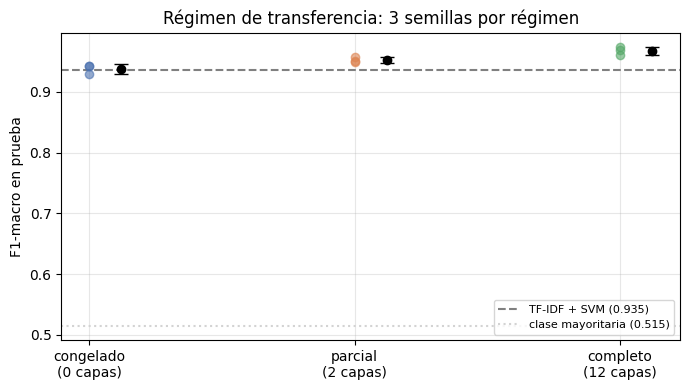

In [ ]:
# Gráfico: F1-macro en prueba por régimen (cada punto una semilla) frente a la línea base
colores = {"congelado": "#4C72B0", "parcial": "#DD8452", "completo": "#55A868"}
fig, ax = plt.subplots(figsize=(7, 4))
for i, regimen in enumerate(CONFIG["regimenes"]):
    s = B[B["regimen"] == regimen]["test_f1_macro"]
    ax.scatter([i] * len(s), s, color=colores.get(regimen), alpha=.6, zorder=3)
    ax.errorbar(i + 0.12, s.mean(), yerr=s.std() if len(s) > 1 else 0, fmt="o", color="black",
                capsize=5, zorder=4)
ax.axhline(mt["f1_macro"], ls="--", color="gray", label=f"TF-IDF + SVM ({mt['f1_macro']:.3f})")
ax.axhline(0.5145, ls=":", color="lightgray", label="clase mayoritaria (0.515)")
ax.set_xticks(range(len(CONFIG["regimenes"])), [f"{k}\n({CONFIG['regimenes'][k]['capas_abiertas']} capas)"
                                                for k in CONFIG["regimenes"]])
ax.set_ylabel("F1-macro en prueba"); ax.set_title("Régimen de transferencia: 3 semillas por régimen")
ax.legend(loc="lower right", fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(DIR_BASE, "f1_prueba_por_regimen.png"), dpi=150); plt.show()

## §18 · ¿Las diferencias son reales? Comparaciones por pares

Las tres semillas de cada régimen se emparejan (misma semilla, mismo orden de lotes) y sobre las 449
noticias de prueba se aplica la **prueba de McNemar exacta**: solo cuentan las noticias en las que un
modelo acierta y el otro falla. También se compara cada régimen contra TF-IDF + SVM. Se reporta además el
intervalo de Wilson al 95 % de la exactitud de cada corrida, como en la Fase 2.

Ojo al leer: con tres comparaciones por par, un p < 0,05 aislado no basta; lo que importa es si la dirección
y la significancia se repiten en las tres semillas.

In [ ]:
def wilson(aciertos, n, z=1.96):
    p = aciertos / n
    centro = (p + z*z/(2*n)) / (1 + z*z/n)
    margen = z * math.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return centro - margen, centro + margen


def mcnemar(acierta_a, acierta_b):
    b = int(np.sum(acierta_a & ~acierta_b))
    c = int(np.sum(~acierta_a & acierta_b))
    p = binomtest(b, b + c, 0.5).pvalue if b + c > 0 else 1.0
    return b, c, p


def aciertos(dir_corrida):
    p = pd.read_csv(os.path.join(dir_corrida, "pred_test.csv")).sort_values("row_id")
    return (p["y_true"] == p["y_pred"]).values

y_test = SPLITS["test"].sort_values("row_id")[COL_LABEL].values
ac_tfidf = (pd.Series(TFIDF["test"]["pred"], index=SPLITS["test"]["row_id"]).sort_index().values == y_test)

ACIERTOS = {(r.regimen, r.seed): aciertos(r.dir) for r in B.itertuples()}
regs = list(CONFIG["regimenes"])
pares = [(a, b) for i, a in enumerate(regs) for b in regs[i+1:]]
filas = []
for seed in CONFIG["seeds_evaluacion"]:
    for a, b in pares:
        if (a, seed) in ACIERTOS and (b, seed) in ACIERTOS:
            n_a, n_b, p = mcnemar(ACIERTOS[(a, seed)], ACIERTOS[(b, seed)])
            filas.append({"semilla": seed, "comparación": f"{a} vs {b}", f"solo acierta A": n_a,
                          "solo acierta B": n_b, "p McNemar": p})
    for a in regs:
        if (a, seed) in ACIERTOS:
            n_a, n_b, p = mcnemar(ACIERTOS[(a, seed)], ac_tfidf)
            filas.append({"semilla": seed, "comparación": f"{a} vs TF-IDF", "solo acierta A": n_a,
                          "solo acierta B": n_b, "p McNemar": p})
tabla_mcnemar = pd.DataFrame(filas)
tabla_mcnemar.to_csv(os.path.join(DIR_BASE, "mcnemar_prueba.csv"), index=False)
print(tabla_mcnemar.round(4).to_string(index=False))

print("\nExactitud en prueba con IC 95 % de Wilson:")
for (regimen, seed), ac in ACIERTOS.items():
    lo, hi = wilson(ac.sum(), len(ac))
    print(f"  {regimen:<10} semilla {seed:<5} {ac.mean():.4f} [{lo:.4f}, {hi:.4f}]")
lo, hi = wilson(ac_tfidf.sum(), len(ac_tfidf))
print(f"  {'TF-IDF':<10} {'':<13} {ac_tfidf.mean():.4f} [{lo:.4f}, {hi:.4f}]")

 semilla           comparación  solo acierta A  solo acierta B  p McNemar
      42  congelado vs parcial              12              16     0.5716
      42 congelado vs completo               2              14     0.0042
      42   parcial vs completo               3              11     0.0574
      42   congelado vs TF-IDF              19              16     0.7359
      42     parcial vs TF-IDF              19              12     0.2810
      42    completo vs TF-IDF              20               5     0.0041
    2026  congelado vs parcial               7              20     0.0192
    2026 congelado vs completo               2              16     0.0013
    2026   parcial vs completo               6               7     1.0000
    2026   congelado vs TF-IDF              19              22     0.7552
    2026     parcial vs TF-IDF              20              10     0.0987
    2026    completo vs TF-IDF              20               9     0.0614
       7  congelado vs parcial        

## §19 · Dinámica: curvas por época de todas las corridas

Una fila por régimen: a la izquierda las pérdidas de entrenamiento (continua) y validación (discontinua),
a la derecha el F1-macro de validación. Cada color es una semilla de la fase B. Qué buscar:

- **Congelado**: si la pérdida de entrenamiento baja poco y se aplana alto, la cabeza no encuentra en el
  vector `[CLS]` preentrenado una separación lineal de las clases: falta capacidad, no sobra.
- **Completo**: si la pérdida de entrenamiento llega casi a cero mientras la de validación sube, hay
  sobreajuste, y la parada temprana es la que salva el resultado.
- **Colapso**: el patrón de la Fase 2 (la pérdida de validación quieta mientras el MCC cae a cero porque
  el modelo responde siempre una clase). Si aparece en alguna semilla, se ve aquí y se reporta.

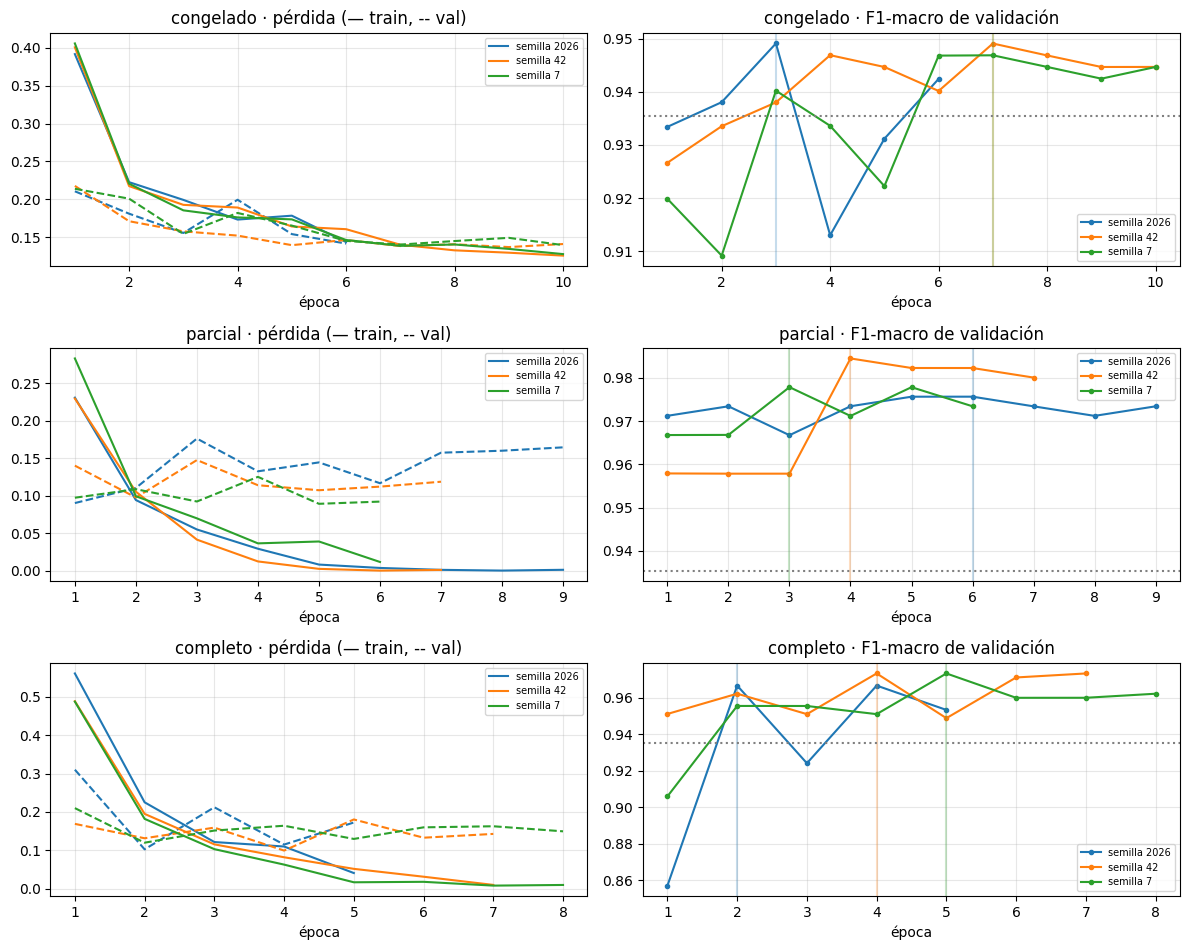

Detección automática de colapso (MCC de validación = 0 en alguna época):
  ⚠️  completo__lr4.10e-05__seed16: colapsó en las épocas [2]
  (fin de la lista)


In [ ]:
fig, axes = plt.subplots(len(regs), 2, figsize=(12, 3.2 * len(regs)), squeeze=False)
for i, regimen in enumerate(regs):
    s = B[B["regimen"] == regimen]
    for j, fila in enumerate(s.itertuples()):
        h = pd.read_csv(os.path.join(fila.dir, "historial.csv"))
        c = f"C{j}"
        axes[i, 0].plot(h["epoca"], h["train_loss"], "-", color=c, label=f"semilla {fila.seed}")
        axes[i, 0].plot(h["epoca"], h["val_loss"], "--", color=c)
        axes[i, 1].plot(h["epoca"], h["val_f1_macro"], "-o", ms=3, color=c, label=f"semilla {fila.seed}")
        axes[i, 1].axvline(fila.mejor_epoca, color=c, alpha=.25)
    axes[i, 0].set_title(f"{regimen} · pérdida (— train, -- val)"); axes[i, 0].set_xlabel("época")
    axes[i, 1].set_title(f"{regimen} · F1-macro de validación"); axes[i, 1].set_xlabel("época")
    axes[i, 1].axhline(mt["f1_macro"], ls=":", color="gray")
    for ax in axes[i]:
        ax.grid(alpha=.3); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(DIR_BASE, "curvas_por_regimen.png"), dpi=150); plt.show()

print("Detección automática de colapso (MCC de validación = 0 en alguna época):")
for r in corridas.itertuples():
    h = pd.read_csv(os.path.join(r.dir, "historial.csv"))
    if (h["val_mcc"].abs() < 1e-9).any():
        print(f"  ⚠️  {os.path.basename(r.dir)}: colapsó en las épocas {h.loc[h['val_mcc'].abs()<1e-9,'epoca'].tolist()}")
print("  (fin de la lista)")

## §20 · Reconciliación con la Fase 2: todas las cifras del ajuste completo

La retroalimentación de la Fase 2 señaló que el repositorio tenía dos resultados distintos con los mismos
hiperparámetros y que el informe solo reportaba uno. En realidad son tres. Esta tabla los pone juntos con
las corridas de este cuaderno que usan exactamente esa configuración (régimen completo, lr 4,1e-5), para
que el informe reporte la distribución y no la mejor corrida.

Una aclaración para el informe: los pesos que carga `auditoria_interpretabilidad_modelo.ipynb` (huella
SHA-256 `c377fa37…`) vienen de la corrida del 22 de septiembre, la de exactitud 0,951; no de la de 0,969.

In [ ]:
fase2 = pd.DataFrame([
    {"origen": "Fase 2 · salida_bayesiana/ (22-sep, Keras)", "test_accuracy": 0.951, "test_f1_macro": 0.951, "test_mcc": 0.9026},
    {"origen": "Fase 2 · finetuning_bayesiano_colombia.ipynb (raíz, Keras)", "test_accuracy": 0.9644, "test_f1_macro": 0.9643, "test_mcc": 0.9287},
    {"origen": "Fase 2 · Segunda entrega/…EJECUTADO3259 (5-oct, Keras)", "test_accuracy": 0.9688, "test_f1_macro": 0.9688, "test_mcc": 0.9377},
])
mismo = corridas[(corridas["regimen"] == "completo") & (np.isclose(corridas["lr"], 4.0983871094082436e-05))]
estas = pd.DataFrame({"origen": [f"Fase 3 · este cuaderno (PyTorch, semilla {s})" for s in mismo["seed"]],
                      "test_accuracy": mismo["test_accuracy"].values,
                      "test_f1_macro": mismo["test_f1_macro"].values, "test_mcc": mismo["test_mcc"].values})
recon = pd.concat([fase2, estas], ignore_index=True)
recon.to_csv(os.path.join(DIR_BASE, "reconciliacion_fase2.csv"), index=False)
print(recon.round(4).to_string(index=False))
print(f"\nRango de F1-macro en prueba con la misma configuración: "
      f"{recon['test_f1_macro'].min():.4f} – {recon['test_f1_macro'].max():.4f} "
      f"(media {recon['test_f1_macro'].mean():.4f}, n = {len(recon)})")

                                                    origen  test_accuracy  test_f1_macro  test_mcc
                Fase 2 · salida_bayesiana/ (22-sep, Keras)         0.9510         0.9510    0.9026
Fase 2 · finetuning_bayesiano_colombia.ipynb (raíz, Keras)         0.9644         0.9643    0.9287
    Fase 2 · Segunda entrega/…EJECUTADO3259 (5-oct, Keras)         0.9688         0.9688    0.9377
              Fase 3 · este cuaderno (PyTorch, semilla 16)         0.8820         0.8820    0.7654

Rango de F1-macro en prueba con la misma configuración: 0.8820 – 0.9688 (media 0.9415, n = 4)


## §21 · Pesos del régimen elegido

Se guarda la corrida de la fase B del régimen elegido con mayor F1-macro en **validación** (no en prueba),
con `save_pretrained` y su huella SHA-256, para que la auditoría y el informe usen un modelo identificable.
Se reentrena con su semilla porque las corridas no guardan pesos (pesarían ~500 MB cada una); la huella
y las métricas de la nueva corrida se comparan con las registradas.

In [ ]:
if CONFIG["guardar_pesos_seleccionado"] and not CONFIG["modo_prueba"]:
    reg = seleccion["regimen_elegido"]
    mejor = B[B["regimen"] == reg].sort_values("val_f1_macro", ascending=False).iloc[0]
    print(f"Reentrenando {reg} · lr {LR_ELEGIDA[reg]:.1e} · semilla {int(mejor['seed'])} para guardar pesos...")
    modelo, res, hist, val, test = entrenar_corrida(reg, LR_ELEGIDA[reg], int(mejor["seed"]), verbose=False)
    d_modelo = os.path.join(DIR_BASE, "modelo_elegido")
    modelo.save_pretrained(d_modelo)
    tokenizer.save_pretrained(d_modelo)
    pesos = [f for f in os.listdir(d_modelo) if f.endswith((".safetensors", ".bin"))]
    huella = hashlib.sha256(open(os.path.join(d_modelo, pesos[0]), "rb").read()).hexdigest()
    info = {"regimen": reg, "lr": LR_ELEGIDA[reg], "seed": int(mejor["seed"]), "sha256_pesos": huella,
            "val_registrada": float(mejor["val_f1_macro"]), "val_reentrenada": res["val"]["f1_macro"],
            "test_reentrenada": res["test"]}
    json.dump(info, open(os.path.join(d_modelo, "procedencia.json"), "w"), indent=2)
    print(json.dumps(info, indent=2))
    print("Si val_reentrenada difiere de val_registrada en los decimales, es el no determinismo de la GPU (§4).")
else:
    print("No se guardan pesos (desactivado o modo prueba).")

Reentrenando parcial · lr 1.5e-04 · semilla 42 para guardar pesos...
{
  "regimen": "parcial",
  "lr": 0.00015,
  "seed": 42,
  "sha256_pesos": "5cee1cedb924c0aa47118b11017a3e89d02f435631f221409dfff30517916585",
  "val_registrada": 0.9845113790453253,
  "val_reentrenada": 0.9845113790453253,
  "test_reentrenada": {
    "accuracy": 0.9510022271714922,
    "f1_macro": 0.9509961503353573,
    "mcc": 0.9025964425601689,
    "precision_falsa": 0.9336283185840708,
    "recall_falsa": 0.9678899082568807,
    "precision_real": 0.968609865470852,
    "recall_real": 0.935064935064935
  }
}
Si val_reentrenada difiere de val_registrada en los decimales, es el no determinismo de la GPU (§4).


## §22 · Resumen para el informe

La celda imprime las cifras para el informe. Las frases de interpretación las escriben ustedes a partir de
ellas; abajo hay una guía de lectura según lo que salga.

In [ ]:
def fila(reg):
    s = B[B["regimen"] == reg]
    return (f"{reg:<10} · {int(s['parametros_entrenables'].iloc[0]):>11,} parámetros · lr {LR_ELEGIDA[reg]:.1e} · "
            f"F1 val {s['val_f1_macro'].mean():.4f} ± {s['val_f1_macro'].std():.4f} · "
            f"F1 prueba {s['test_f1_macro'].mean():.4f} ± {s['test_f1_macro'].std():.4f} · "
            f"MCC prueba {s['test_mcc'].mean():.4f} ± {s['test_mcc'].std():.4f} · "
            f"{s['minutos'].mean():.1f} min/corrida")

texto = [
    "COMPARACIÓN DE REGÍMENES DE TRANSFERENCIA — RoBERTa-BNE, corpus colombiano (3.259)",
    "=" * 100,
    f"Modelo: {MODELO} @ {REVISION}",
    f"Partición: la misma de la Fase 2 (train {len(SPLITS['train'])} · val {len(SPLITS['val'])} · "
    f"test {len(SPLITS['test'])}), verificada fila por fila; 0 grupos con fuga.",
    "Protocolo común: ganador de la búsqueda bayesiana (lote 8, dropout 0.0726, wd 0.00855, "
    "ReduceLROnPlateau 0.33/1, parada 3).",
    f"Tasa elegida por régimen en validación con semilla {CONFIG['seed_seleccion']}; "
    f"evaluación con semillas {CONFIG['seeds_evaluacion']}.",
    "",
    *[fila(r) for r in regs],
    f"{'TF-IDF+SVM':<10} · F1 prueba {mt['f1_macro']:.4f} · MCC prueba {mt['mcc']:.4f}",
    "",
    f"Régimen elegido en validación: {seleccion['regimen_elegido']} ({seleccion['motivo']}).",
    f"Decisión congelada: {seleccion['fecha_decision']}",
]
texto = "\n".join(texto)
print(texto)
with open(os.path.join(DIR_BASE, "resumen_informe.txt"), "w") as f:
    f.write(texto)

COMPARACIÓN DE REGÍMENES DE TRANSFERENCIA — RoBERTa-BNE, corpus colombiano (3.259)
Modelo: IsGarrido/roberta-base-bne @ 3d54a71ddc029cc1f8dd604e3b7bc0da0e2f7cd9
Partición: la misma de la Fase 2 (train 2358 · val 452 · test 449), verificada fila por fila; 0 grupos con fuga.
Protocolo común: ganador de la búsqueda bayesiana (lote 8, dropout 0.0726, wd 0.00855, ReduceLROnPlateau 0.33/1, parada 3).
Tasa elegida por régimen en validación con semilla 16; evaluación con semillas [42, 2026, 7].

congelado  ·     592,130 parámetros · lr 3.0e-04 · F1 val 0.9484 ± 0.0013 · F1 prueba 0.9374 ± 0.0077 · MCC prueba 0.8764 ± 0.0164 · 0.1 min/corrida
parcial    ·  14,767,874 parámetros · lr 1.5e-04 · F1 val 0.9793 ± 0.0046 · F1 prueba 0.9525 ± 0.0046 · MCC prueba 0.9053 ± 0.0094 · 1.1 min/corrida
completo   · 124,644,866 parámetros · lr 2.0e-05 · F1 val 0.9712 ± 0.0038 · F1 prueba 0.9673 ± 0.0068 · MCC prueba 0.9346 ± 0.0136 · 3.3 min/corrida
TF-IDF+SVM · F1 prueba 0.9354 · MCC prueba 0.8710

Régimen e

### Guía de lectura

**Si el completo gana con claridad** (diferencia mayor que la desviación y McNemar consistente en las
tres semillas): el vector preentrenado de RoBERTa-BNE no basta para esta tarea y hay que adaptar el
cuerpo. El costo (decenas de millones de parámetros más y minutos de GPU por corrida) queda justificado.

**Si el parcial empata con el completo**: casi toda la adaptación útil ocurre en las últimas capas. Es la
lectura habitual en transferencia con transformadores (las capas bajas codifican rasgos generales del
idioma) y permite entrenar más barato con el mismo resultado.

**Si el congelado queda lejos de los otros dos y también por debajo de TF-IDF**: la representación
preentrenada, sin adaptar, no separa noticias reales de falsas mejor que contar palabras. Que el ajuste
fino sí lo logre no dice que el modelo aprendió veracidad.

**Lo que ningún resultado de este cuaderno demuestra.** Con la partición actual, el 97,5 % de las noticias
viene de un sitio que publica una sola clase (El Espectador solo aporta verdaderas; Colombiacheck y los
sitios satíricos solo falsas), y la auditoría de interpretabilidad mostró que el modelo marca como falsas
el 29 % de las noticias reales de otros medios reputables frente al 0 % de El Espectador. Un régimen que
gana aquí puede ganar porque reconoce mejor el estilo de cada medio. Separar eso de la veracidad exige
las otras dos tareas de la Fase 3: la partición temporal y una prueba que deje medios completos fuera
del entrenamiento.

**Limitaciones de este experimento**
- Tres semillas por régimen dan una idea de la variabilidad, no un intervalo preciso.
- Las rejillas de tasa son pequeñas (2 a 4 valores); un régimen podría mejorar con otra tasa.
- El protocolo común viene de una búsqueda hecha para el ajuste completo, lo que en principio lo favorece.
  Elegir la tasa por régimen corrige la parte más importante de ese sesgo, pero no toda.
- El parcial se probó con 2 capas abiertas; no se exploró cuántas capas son el punto óptimo.

## §23 · Empaquetar los resultados

Un `.zip` con todas las tablas, figuras, historiales y predicciones (sin los pesos) para subirlo al
repositorio en una carpeta `Tercera entrega/`. La partición `particion_fase2.csv` va incluida: conviene
versionarla para que nadie tenga que volver a calcularla.

In [ ]:
nombre_zip = "resultados_regimenes_fase3"
tmp = shutil.copytree(DIR_BASE, "/tmp/" + nombre_zip, ignore=shutil.ignore_patterns("modelo_elegido"),
                      dirs_exist_ok=True)
archivo = shutil.make_archive(nombre_zip, "zip", tmp)
print(f"✓ {archivo} ({os.path.getsize(archivo)/1e6:.1f} MB)")
if EN_COLAB:
    from google.colab import files
    files.download(archivo)

✓ /content/resultados_regimenes_fase3.zip (0.5 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## §24 · Curva de aprendizaje: ¿el colapso era por tamaño del corpus o por la receta?

En la Fase 1 el profesor escribió: *"125 millones de parámetros ajustándose con 633 noticias de entrenamiento. No hay señal suficiente para mover tantos pesos sin destruir lo que el modelo ya sabía, y por eso colapsó"*, y pidió comparar regímenes para *"decir si el colapso fue por tamaño del corpus o por régimen de ajuste"*.

Con 2.358 noticias el ajuste completo gana (§17). Esta sección repite los tres regímenes con **menos datos de entrenamiento** (300, 633 —el tamaño de la Fase 1—, 1.200 y 2.358), dejando fijos la validación (452), la prueba (449), la tasa de cada régimen elegida en §14, el protocolo de §12 y las semillas 42, 2026 y 7.

**Submuestras:** para cada semilla se baraja el entrenamiento una vez por clase y se toman los primeros *n* de cada clase, manteniendo la proporción real/falsa. Quedan **anidadas** (las 300 dentro de las 633, y así sucesivamente) y cada semilla usa una muestra distinta. Con 2.358 se reutilizan las corridas de la fase B.

**Control:** con 633 noticias se corre además el ajuste completo con la tasa del artículo (1e-5), la que colapsó en la Fase 1. Es un control parcial: la Fase 1 también usaba lote 16, calentamiento y *dropout* 0,15, que aquí no cambian.

**Advertencia:** las 633 noticias salen del corpus ampliado, no son las de la Fase 1. Se compara el **tamaño**, no los mismos datos.

Código 1 — submuestras, función de corrida y estimación de tiempo:

In [35]:
CURVA = {
    "tamanos": [300, 633, 1200, len(SPLITS["train"])],
    "regimenes": ["congelado", "parcial", "completo"],
    "seeds": CONFIG["seeds_evaluacion"],
    # Control: régimen completo con la tasa del artículo, solo en el tamaño de la Fase 1
    "control_articulo": {"regimen": "completo", "lr": 1e-5, "tamanos": [633]},
}
DIR_CURVA = os.path.join(DIR_BASE, "curva_aprendizaje")
os.makedirs(os.path.join(DIR_CURVA, "runs"), exist_ok=True)
N_TRAIN = len(SPLITS["train"])
Y_TRAIN = TOK["train"][2].numpy()


def indices_submuestra(n, seed):
    """Submuestra estratificada y anidada: con una misma semilla, la de 300 está dentro de la de 633."""
    rng = np.random.default_rng(1000 + seed)
    orden = {c: rng.permutation(np.where(Y_TRAIN == c)[0]) for c in (0, 1)}
    n1 = int(round(n * Y_TRAIN.mean()))
    return np.sort(np.concatenate([orden[0][:n - n1], orden[1][:n1]]))


# Comprobaciones: tamaño, balance y anidamiento
for s in CURVA["seeds"]:
    previo = set()
    for n in CURVA["tamanos"]:
        idx = indices_submuestra(n, s)
        assert len(idx) == n and set(previo) <= set(idx)
        previo = idx
print("Submuestras de entrenamiento (proporción de reales):")
for n in CURVA["tamanos"]:
    print(f"  n = {n:>5} · {Y_TRAIN[indices_submuestra(n, CURVA['seeds'][0])].mean():.3f}")


def correr_curva(regimen, lr, n, seed):
    nombre = f"{regimen}__n{n}__lr{lr:.2e}__seed{seed}"
    d = os.path.join(DIR_CURVA, "runs", nombre)
    if os.path.exists(os.path.join(d, "resultado.json")):
        return json.load(open(os.path.join(d, "resultado.json")))

    previa = os.path.join(DIR_RUNS, nombre_corrida(regimen, lr, seed))
    if n == N_TRAIN and os.path.exists(os.path.join(previa, "resultado.json")):
        res = json.load(open(os.path.join(previa, "resultado.json")))   # corrida de la fase B
        res.update({"n_train": n, "reutilizada_de": os.path.basename(previa)})
        os.makedirs(d, exist_ok=True)
        for f in ["historial.csv", "pred_test.csv"]:
            shutil.copy(os.path.join(previa, f), os.path.join(d, f))
        with open(os.path.join(d, "resultado.json"), "w") as f:
            json.dump(res, f, indent=2)
        print(f"  {nombre}: reutilizada de la fase B")
        return res

    idx = torch.tensor(indices_submuestra(n, seed))
    tok_completo, cls_completo = TOK["train"], CLS["train"]
    try:
        TOK["train"] = tuple(t[idx] for t in tok_completo)   # se reemplaza solo el entrenamiento
        CLS["train"] = cls_completo[idx]
        modelo, res, hist, val, test = entrenar_corrida(regimen, lr, seed, verbose=False)
    finally:
        TOK["train"], CLS["train"] = tok_completo, cls_completo   # siempre se restaura
    res.update({"n_train": n, "indices_sha256": hashlib.sha256(idx.numpy().tobytes()).hexdigest()})

    os.makedirs(d + ".tmp", exist_ok=True)
    hist.to_csv(os.path.join(d + ".tmp", "historial.csv"), index=False)
    p, y = test
    pd.DataFrame({"row_id": SPLITS["test"]["row_id"].values, "y_true": y, "prob_real": p[:, 1],
                  "y_pred": p.argmax(1)}).to_csv(os.path.join(d + ".tmp", "pred_test.csv"), index=False)
    with open(os.path.join(d + ".tmp", "resultado.json"), "w") as f:
        json.dump(res, f, indent=2)
    if os.path.exists(d):
        shutil.rmtree(d)
    os.rename(d + ".tmp", d)
    del modelo
    torch.cuda.empty_cache()
    print(f"  {nombre}: F1 val {res['val']['f1_macro']:.4f} · MCC val {res['val']['mcc']:.4f} · "
          f"mejor época {res['mejor_epoca']} · {res['minutos']:.1f} min")
    return res


# Estimación de tiempo con la velocidad medida en §13 (supone ~7 épocas por corrida)
plan = [(r, LR_ELEGIDA[r], n, s) for n in CURVA["tamanos"] for r in CURVA["regimenes"] for s in CURVA["seeds"]]
c = CURVA["control_articulo"]
plan += [(c["regimen"], c["lr"], n, s) for n in c["tamanos"] for s in CURVA["seeds"]]
nuevas = [x for x in plan if x[2] != N_TRAIN]
seg = sum(velocidad[r] * math.ceil(n / CONFIG["batch_size"]) * 7 for r, _, n, _ in nuevas)
print(f"\n{len(plan)} corridas en el plan ({len(plan) - len(nuevas)} se reutilizan de la fase B).")
print(f"Estimación: ≈ {seg/60:.0f} min de entrenamiento, más la evaluación de cada época.")

Submuestras de entrenamiento (proporción de reales):
  n =   300 · 0.497
  n =   633 · 0.496
  n =  1200 · 0.497
  n =  2358 · 0.497

39 corridas en el plan (9 se reutilizan de la fase B).
Estimación: ≈ 61 min de entrenamiento, más la evaluación de cada época.


In [34]:
import builtins
sum = builtins.sum   # restaura la función que quedó tapada en la sesión

seg = sum(velocidad[r] * math.ceil(n / CONFIG["batch_size"]) * 7 for r, _, n, _ in nuevas)
print(f"{len(plan)} corridas en el plan ({len(plan) - len(nuevas)} se reutilizan de la fase B).")
print(f"Estimación: ≈ {seg/60:.0f} min de entrenamiento, más la evaluación de cada época.")

39 corridas en el plan (9 se reutilizan de la fase B).
Estimación: ≈ 61 min de entrenamiento, más la evaluación de cada época.


Código 2 — ejecución. Va de menor a mayor tamaño. Cada corrida se guarda al terminar, así que si Colab se desconecta, vuelve a ejecutar desde el bloque 1 y retoma donde quedó.

In [36]:
t0 = time.time()
for regimen, lr, n, seed in sorted(plan, key=lambda x: (x[2], x[0], x[1], x[3])):
    correr_curva(regimen, lr, n, seed)
print(f"\nCurva completa en {(time.time() - t0)/60:.1f} min.")

  completo__n300__lr2.00e-05__seed7: F1 val 0.9267 · MCC val 0.8561 · mejor época 8 · 1.6 min
  completo__n300__lr2.00e-05__seed42: F1 val 0.9557 · MCC val 0.9123 · mejor época 15 · 1.8 min
  completo__n300__lr2.00e-05__seed2026: F1 val 0.9244 · MCC val 0.8540 · mejor época 12 · 1.3 min
  congelado__n300__lr3.00e-04__seed7: F1 val 0.9024 · MCC val 0.8061 · mejor época 6 · 0.0 min
  congelado__n300__lr3.00e-04__seed42: F1 val 0.9447 · MCC val 0.8893 · mejor época 15 · 0.0 min
  congelado__n300__lr3.00e-04__seed2026: F1 val 0.9071 · MCC val 0.8170 · mejor época 9 · 0.0 min
  parcial__n300__lr1.50e-04__seed7: F1 val 0.9045 · MCC val 0.8122 · mejor época 3 · 0.2 min
  parcial__n300__lr1.50e-04__seed42: F1 val 0.9646 · MCC val 0.9295 · mejor época 5 · 0.3 min
  parcial__n300__lr1.50e-04__seed2026: F1 val 0.9313 · MCC val 0.8629 · mejor época 5 · 0.3 min
  completo__n633__lr1.00e-05__seed7: F1 val 0.9036 · MCC val 0.8226 · mejor época 5 · 1.1 min
  completo__n633__lr1.00e-05__seed42: F1 val 

Código 3 — tabla de resultados. Incluye TF-IDF + SVM entrenado con las mismas submuestras y dos diagnósticos de colapso. “No despegó” significa que el MCC de validación nunca pasó de 0,2. La “pérdida en la época 1” en torno a 0,693 (ln 2) significa que el modelo no empezó a aprender.

In [37]:
filas = []
for ruta in sorted(glob.glob(os.path.join(DIR_CURVA, "runs", "*", "resultado.json"))):
    r = json.load(open(ruta))
    h = pd.read_csv(os.path.join(os.path.dirname(ruta), "historial.csv"))
    es_control = r["regimen"] == CURVA["control_articulo"]["regimen"] and \
        np.isclose(r["lr"], CURVA["control_articulo"]["lr"])
    filas.append({
        "modelo": f"{r['regimen']} (lr {r['lr']:.0e}, control)" if es_control else r["regimen"],
        "regimen": r["regimen"], "control": es_control, "n_train": r["n_train"], "seed": r["seed"],
        "val_f1": r["val"]["f1_macro"], "test_f1": r["test"]["f1_macro"], "test_mcc": r["test"]["mcc"],
        "no_despego": bool(h["val_mcc"].max() < 0.2), "loss_epoca1": h["train_loss"].iloc[0],
        "loss_min": h["train_loss"].min(), "mejor_epoca": r["mejor_epoca"], "minutos": r["minutos"],
        "dir": os.path.dirname(ruta)})
curva = pd.DataFrame(filas)

# TF-IDF + SVM sobre las mismas submuestras
tf_cfg = CONFIG["tfidf"]
filas_tfidf = []
for n in CURVA["tamanos"]:
    for s in CURVA["seeds"]:
        idx = indices_submuestra(n, s)
        sub = SPLITS["train"].iloc[idx]
        v = TfidfVectorizer(ngram_range=tf_cfg["ngram_range"], min_df=tf_cfg["min_df"],
                            max_features=tf_cfg["max_features"], sublinear_tf=tf_cfg["sublinear_tf"],
                            strip_accents="unicode", lowercase=True)
        clf = LinearSVC(C=tf_cfg["C"], max_iter=5000, random_state=16).fit(v.fit_transform(sub["texto"]), sub[COL_LABEL])
        filas_tfidf.append({"modelo": "TF-IDF + SVM", "regimen": "tfidf", "control": False, "n_train": n, "seed": s,
                            "val_f1": f1_score(SPLITS["val"][COL_LABEL], clf.predict(v.transform(SPLITS["val"]["texto"])), average="macro"),
                            "test_pred": clf.predict(v.transform(SPLITS["test"]["texto"]))})
for f in filas_tfidf:
    f["test_f1"] = f1_score(SPLITS["test"][COL_LABEL], f["test_pred"], average="macro")
    f["test_mcc"] = matthews_corrcoef(SPLITS["test"][COL_LABEL], f["test_pred"])
tfidf_curva = pd.DataFrame(filas_tfidf)

todo = pd.concat([curva, tfidf_curva.drop(columns="test_pred")], ignore_index=True)
resumen = (todo.groupby(["modelo", "n_train"])
               .agg(val_f1=("val_f1", "mean"), val_sd=("val_f1", "std"), test_f1=("test_f1", "mean"),
                    test_sd=("test_f1", "std"), test_mcc=("test_mcc", "mean"),
                    no_despego=("no_despego", lambda x: "—" if x.isna().all() else f"{int(x.fillna(False).sum())}/{len(x)}"),
                    loss_epoca1=("loss_epoca1", "mean"), semillas=("seed", "count"))
               .reset_index())
orden_modelos = ["congelado", "parcial", "completo"] + \
    [m for m in resumen["modelo"].unique() if "control" in m] + ["TF-IDF + SVM"]
resumen["modelo"] = pd.Categorical(resumen["modelo"], orden_modelos, ordered=True)
resumen = resumen.sort_values(["n_train", "modelo"])
resumen.to_csv(os.path.join(DIR_CURVA, "resumen_curva.csv"), index=False)
curva.drop(columns="dir").to_csv(os.path.join(DIR_CURVA, "corridas_curva.csv"), index=False)
print(resumen.round(4).to_string(index=False))

                      modelo  n_train  val_f1  val_sd  test_f1  test_sd  test_mcc no_despego  loss_epoca1  semillas
                   congelado      300  0.9180  0.0232   0.8974   0.0112    0.7953        0/3       0.6652         3
                     parcial      300  0.9335  0.0301   0.9202   0.0186    0.8435        0/3       0.5368         3
                    completo      300  0.9356  0.0174   0.9300   0.0129    0.8618        0/3       0.6984         3
                TF-IDF + SVM      300  0.8731  0.0068   0.8708   0.0059    0.7439          —          NaN         3
                   congelado      633  0.9336  0.0059   0.9042   0.0112    0.8087        0/3       0.5962         3
                     parcial      633  0.9550  0.0068   0.9428   0.0084    0.8860        0/3       0.4237         3
                    completo      633  0.9490  0.0119   0.9383   0.0052    0.8777        0/3       0.6922         3
completo (lr 1e-05, control)      633  0.8895  0.0500   0.8850   0.0435 

/tmp/ipykernel_420/3183384140.py:39: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  no_despego=("no_despego", lambda x: "—" if x.isna().all() else f"{int(x.fillna(False).sum())}/{len(x)}"),


Código 4 — gráfico de la curva:

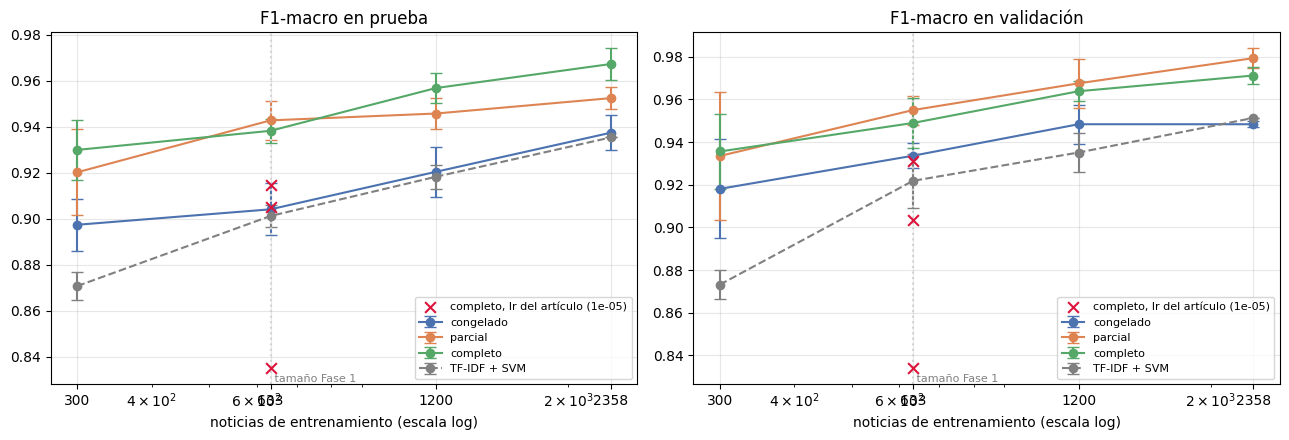

In [38]:
colores = {"congelado": "#4C72B0", "parcial": "#DD8452", "completo": "#55A868", "TF-IDF + SVM": "gray"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col, titulo in [(axes[0], "test_f1", "F1-macro en prueba"), (axes[1], "val_f1", "F1-macro en validación")]:
    for modelo in ["congelado", "parcial", "completo", "TF-IDF + SVM"]:
        s = todo[todo["modelo"] == modelo].groupby("n_train")[col].agg(["mean", "std"]).reset_index()
        ax.errorbar(s["n_train"], s["mean"], yerr=s["std"].fillna(0), marker="o", capsize=4,
                    color=colores[modelo], ls="--" if modelo.startswith("TF") else "-", label=modelo)
    ctrl = todo[todo["control"] == True]
    if len(ctrl):
        ax.scatter(ctrl["n_train"], ctrl[col], marker="x", s=60, color="crimson",
                   label=f"completo, lr del artículo ({CURVA['control_articulo']['lr']:.0e})", zorder=5)
    ax.axvline(633, color="lightgray", ls=":")
    ax.text(633, ax.get_ylim()[0], " tamaño Fase 1", fontsize=8, color="gray", va="bottom")
    ax.set_xscale("log"); ax.set_xticks(CURVA["tamanos"], [str(n) for n in CURVA["tamanos"]])
    ax.set_xlabel("noticias de entrenamiento (escala log)"); ax.set_title(titulo)
    ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(DIR_CURVA, "curva_aprendizaje.png"), dpi=150); plt.show()

Código 5 — McNemar por tamaño, para ver si los regímenes se cruzan:

In [39]:
def aciertos_de(d):
    p = pd.read_csv(os.path.join(d, "pred_test.csv")).sort_values("row_id")
    return (p["y_true"] == p["y_pred"]).values

base = curva[~curva["control"]]
filas = []
for n in CURVA["tamanos"]:
    for s in CURVA["seeds"]:
        def ac(reg):
            fila = base[(base["regimen"] == reg) & (base["n_train"] == n) & (base["seed"] == s)]
            return aciertos_de(fila["dir"].iloc[0]) if len(fila) else None
        for a, b in [("completo", "congelado"), ("completo", "parcial"), ("parcial", "congelado")]:
            A, Bc = ac(a), ac(b)
            if A is not None and Bc is not None:
                sa, sb, p = mcnemar(A, Bc)
                filas.append({"n_train": n, "semilla": s, "comparación": f"{a} vs {b}",
                              "dif. aciertos": int(A.sum() - Bc.sum()), "solo A": sa, "solo B": sb, "p": p})
pares = pd.DataFrame(filas)
pares.to_csv(os.path.join(DIR_CURVA, "mcnemar_curva.csv"), index=False)

lectura = (pares.assign(gana_A=pares["dif. aciertos"] > 0, sig=pares["p"] < 0.05)
                .groupby(["n_train", "comparación"])
                .agg(semillas_gana_A=("gana_A", "sum"), semillas_significativas=("sig", "sum"),
                     dif_media_aciertos=("dif. aciertos", "mean"))
                .reset_index())
print("Dirección y significancia por tamaño (A = primer régimen de la comparación):")
print(lectura.round(1).to_string(index=False))
print("\nDetalle por semilla:")
print(pares.round(4).to_string(index=False))

Dirección y significancia por tamaño (A = primer régimen de la comparación):
 n_train           comparación  semillas_gana_A  semillas_significativas  dif_media_aciertos
     300 completo vs congelado                3                        2                14.7
     300   completo vs parcial                2                        0                 4.3
     300  parcial vs congelado                3                        1                10.3
     633 completo vs congelado                3                        2                15.3
     633   completo vs parcial                1                        0                -2.0
     633  parcial vs congelado                3                        2                17.3
    1200 completo vs congelado                3                        2                16.3
    1200   completo vs parcial                2                        0                 5.0
    1200  parcial vs congelado                3                        1              

Código 6 — resumen de hechos y descarga del ZIP:

In [40]:
LN2 = math.log(2)
print("HECHOS PARA LA PREGUNTA DEL PROFESOR")
print("=" * 90)
for n in CURVA["tamanos"]:
    r = resumen[resumen["n_train"] == n].set_index("modelo")
    print(f"\nn = {n}")
    for m in r.index:
        if m not in r.index or pd.isna(r.loc[m, "test_f1"]):
            continue
        extra = ""
        if not pd.isna(r.loc[m, "loss_epoca1"]):
            extra = (f" · no despegó {r.loc[m, 'no_despego']} · pérdida época 1 {r.loc[m, 'loss_epoca1']:.3f}"
                     f"{' (≈ ln 2)' if abs(r.loc[m, 'loss_epoca1'] - LN2) < 0.01 else ''}")
        print(f"  {str(m):<32} prueba {r.loc[m, 'test_f1']:.4f} ± {0 if pd.isna(r.loc[m, 'test_sd']) else r.loc[m, 'test_sd']:.4f}"
              f" · val {r.loc[m, 'val_f1']:.4f}{extra}")
    mejor_val = r.drop(index=[i for i in r.index if "TF-IDF" in str(i) or "control" in str(i)])["val_f1"].idxmax()
    print(f"  → mejor régimen por validación: {mejor_val}")

with open(os.path.join(DIR_CURVA, "hechos_curva.txt"), "w") as f:
    f.write(resumen.round(4).to_string(index=False) + "\n\n" + lectura.round(1).to_string(index=False))

archivo = shutil.make_archive("curva_aprendizaje_fase3", "zip", DIR_CURVA)
print(f"\n✓ Resultados de la curva en {archivo}")
if EN_COLAB:
    from google.colab import files
    files.download(archivo)

HECHOS PARA LA PREGUNTA DEL PROFESOR

n = 300
  congelado                        prueba 0.8974 ± 0.0112 · val 0.9180 · no despegó 0/3 · pérdida época 1 0.665
  parcial                          prueba 0.9202 ± 0.0186 · val 0.9335 · no despegó 0/3 · pérdida época 1 0.537
  completo                         prueba 0.9300 ± 0.0129 · val 0.9356 · no despegó 0/3 · pérdida época 1 0.698 (≈ ln 2)
  TF-IDF + SVM                     prueba 0.8708 ± 0.0059 · val 0.8731
  → mejor régimen por validación: completo

n = 633
  congelado                        prueba 0.9042 ± 0.0112 · val 0.9336 · no despegó 0/3 · pérdida época 1 0.596
  parcial                          prueba 0.9428 ± 0.0084 · val 0.9550 · no despegó 0/3 · pérdida época 1 0.424
  completo                         prueba 0.9383 ± 0.0052 · val 0.9490 · no despegó 0/3 · pérdida época 1 0.692 (≈ ln 2)
  completo (lr 1e-05, control)     prueba 0.8850 ± 0.0435 · val 0.8895 · no despegó 0/3 · pérdida época 1 0.692 (≈ ln 2)
  TF-IDF + SVM      

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>